# مشروع الكشف عن الاحتيال في بطاقات الائتمان
**Credit Card Fraud Detection Using Supervised and Unsupervised Learning**

## وصف المشروع
يهدف هذا المشروع إلى بناء نظام ذكي للكشف عن معاملات بطاقات الائتمان الاحتيالية باستخدام تقنيات التعلم الآلي المُوجَّه والتعلم الآلي غير المُوجَّه. يعتمد النظام على تحليل بيانات المعاملات المالية، وتدريب نماذج التصنيف للكشف عن الاحتيال، واستخدام خوارزميات اكتشاف الشذوذ للتعرّف على الأنماط غير الطبيعية، ثم مقارنة أداء النماذج باستخدام مقاييس تقييم مناسبة للبيانات غير المتوازنة، بهدف تحسين اكتشاف المعاملات الاحتيالية وتقليل الإنذارات الكاذبة.

In [ ]:

import pandas as pd
from pathlib import Path

# البحث عن ملف البيانات في المسارات الشائعة داخل Google Colab
possible_paths = [
    Path("/content/creditcard.csv"),
    Path("/content/drive/MyDrive/creditcard.csv"),
]

file_path = next(
    (path for path in possible_paths if path.is_file()),
    None
)

if file_path is None:
    # البحث داخل مجلد /content إذا كان الملف داخل مجلد فرعي
    matches = list(Path("/content").rglob("creditcard.csv"))
    if matches:
        file_path = matches[0]

if file_path is None:
    raise FileNotFoundError(
        "لم أجد creditcard.csv داخل /content. "
        "تحقق من اسم الملف أو مكانه في Google Colab."
    )

# قراءة الملف الموجود مسبقًا
df = pd.read_csv(file_path)

# عرض ملخص البيانات
print("تمت قراءة البيانات بنجاح.")
print(f"مسار الملف: {file_path}")
print(f"عدد الصفوف: {df.shape[0]:,}")
print(f"عدد الأعمدة: {df.shape[1]}")

print("\nأسماء الأعمدة:")
print(df.columns.tolist())

print("\nأول خمس معاملات:")
display(df.head())

print("\nمعلومات أنواع البيانات:")
df.info()


تمت قراءة البيانات بنجاح.
مسار الملف: /content/creditcard.csv
عدد الصفوف: 284,807
عدد الأعمدة: 31

أسماء الأعمدة:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

أول خمس معاملات:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



معلومات أنواع البيانات:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null

# المرحلة الثانية: فحص جودة البيانات والتحقق من سلامتها

## الهدف
تهدف هذه المرحلة إلى تقييم جودة مجموعة البيانات قبل البدء في التحليل الاستكشافي وبناء نماذج تعلم الآلة.

## الإجراءات
1. التحقق من أبعاد مجموعة البيانات وأسماء الأعمدة.
2. تحديد أنواع البيانات لكل عمود.
3. فحص القيم المفقودة.
4. اكتشاف الصفوف المكررة.
5. التحقق من وجود قيم غير صالحة في البيانات الرقمية.

## المنهجية الهندسية
لن نحذف أي صفوف أو أعمدة في هذه المرحلة؛ لأن اتخاذ قرار التنظيف قبل فهم طبيعة البيانات قد يؤدي إلى فقدان معلومات مهمة. سنكتفي بالتشخيص وتسجيل النتائج، ثم نحدد المعالجة المناسبة بناءً على الأدلة.

**المخرجات المتوقعة:** تقرير أولي عن سلامة البيانات يساعدنا على اتخاذ قرارات صحيحة قبل التدريب.

In [ ]:

import numpy as np
import pandas as pd

# 1. التحقق من وجود إطار البيانات
assert "df" in globals(), (
    "لم يتم العثور على df. شغّل خلية قراءة البيانات أولًا."
)

# 2. عرض الأبعاد وأسماء الأعمدة
print("=" * 60)
print("1. الأبعاد والبنية العامة")
print("=" * 60)

print(f"عدد الصفوف: {df.shape[0]:,}")
print(f"عدد الأعمدة: {df.shape[1]:,}")
print(f"أسماء الأعمدة:\n{df.columns.tolist()}")

# 3. فحص أنواع البيانات
print("\n" + "=" * 60)
print("2. أنواع البيانات")
print("=" * 60)

display(
    pd.DataFrame({
        "Data_Type": df.dtypes.astype(str),
        "Missing_Count": df.isna().sum(),
        "Missing_Percentage": (
            df.isna().mean() * 100
        ).round(4),
        "Unique_Values": df.nunique(dropna=True)
    })
)

# 4. فحص الصفوف المكررة
print("\n" + "=" * 60)
print("3. فحص الصفوف المكررة")
print("=" * 60)

duplicate_count = int(df.duplicated().sum())

print(f"عدد الصفوف المكررة بالكامل: {duplicate_count:,}")
print(
    f"نسبة الصفوف المكررة: "
    f"{duplicate_count / len(df) * 100:.4f}%"
)

# 5. فحص القيم اللانهائية في الأعمدة الرقمية
print("\n" + "=" * 60)
print("4. فحص القيم اللانهائية")
print("=" * 60)

numeric_df = df.select_dtypes(include=np.number)

infinite_counts = pd.Series(
    np.isinf(numeric_df.to_numpy()).sum(axis=0),
    index=numeric_df.columns
)

print(f"إجمالي القيم اللانهائية: {int(infinite_counts.sum()):,}")

if infinite_counts.any():
    display(infinite_counts[infinite_counts > 0].to_frame(
        "Infinite_Count"
    ))
else:
    print("لا توجد قيم لانهائية في الأعمدة الرقمية.")

# 6. ملخص القيم المفقودة
print("\n" + "=" * 60)
print("5. ملخص القيم المفقودة")
print("=" * 60)

total_missing = int(df.isna().sum().sum())

print(f"إجمالي القيم المفقودة: {total_missing:,}")

if total_missing == 0:
    print("لا توجد قيم مفقودة.")
else:
    display(
        df.isna().sum()
        .loc[lambda x: x > 0]
        .sort_values(ascending=False)
        .to_frame("Missing_Count")
    )


1. الأبعاد والبنية العامة
عدد الصفوف: 284,807
عدد الأعمدة: 31
أسماء الأعمدة:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

2. أنواع البيانات


,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
Time,float64,0,0.0,124592
V1,float64,0,0.0,275663
V2,float64,0,0.0,275663
V3,float64,0,0.0,275663
V4,float64,0,0.0,275663
V5,float64,0,0.0,275663
V6,float64,0,0.0,275663
V7,float64,0,0.0,275663
V8,float64,0,0.0,275663
V9,float64,0,0.0,275663



3. فحص الصفوف المكررة
عدد الصفوف المكررة بالكامل: 1,081
نسبة الصفوف المكررة: 0.3796%

4. فحص القيم اللانهائية
إجمالي القيم اللانهائية: 0
لا توجد قيم لانهائية في الأعمدة الرقمية.

5. ملخص القيم المفقودة
إجمالي القيم المفقودة: 0
لا توجد قيم مفقودة.


# المرحلة الثالثة: تحليل توزيع الفئات وتشخيص عدم التوازن

## الهدف
تهدف هذه المرحلة إلى تحليل عمود الهدف `Class` وتحديد حجم عدم التوازن بين المعاملات الطبيعية والمعاملات الاحتيالية، بالإضافة إلى فحص الصفوف المكررة من منظور تصنيفي.

## الإجراءات
1. حساب عدد المعاملات الطبيعية والاحتيالية ونسبة كل فئة.
2. التحقق من القيم الموجودة في عمود `Class` والتأكد من أن التصنيف ثنائي.
3. حساب نسبة عدم التوازن بين الفئتين.
4. فحص توزيع الفئات داخل الصفوف المكررة بالكامل.
5. اكتشاف الحالات التي تتطابق فيها الميزات بينما تختلف تسمية المعاملة.

## المنهجية الهندسية
في كشف الاحتيال، تكون الفئة الاحتيالية نادرة مقارنة بالفئة الطبيعية. لذلك قد يحقق النموذج دقة ظاهرية مرتفعة حتى لو فشل في اكتشاف معظم حالات الاحتيال.

لن نحذف الصفوف المكررة أو نستخدم تقنيات موازنة البيانات في هذه المرحلة. سنجمع الأدلة أولًا، ثم نحدد سياسة معالجة البيانات قبل تدريب النماذج.

**المخرجات المتوقعة:** تقرير رقمي يوضح توزيع الفئات، وشدة عدم التوازن، ومدى تأثير التكرارات المحتمل في بناء نموذج موثوق.

In [ ]:

import pandas as pd
import numpy as np

# التأكد من وجود عمود الهدف
assert "Class" in df.columns, "لم يتم العثور على العمود Class."

# 1. التحقق من قيم عمود الهدف
print("=" * 65)
print("1. التحقق من قيم عمود الهدف")
print("=" * 65)

print("القيم الموجودة في Class:")
print(sorted(df["Class"].dropna().unique().tolist()))

if df["Class"].isna().any():
    raise ValueError("عمود Class يحتوي على قيم مفقودة.")

if set(df["Class"].unique()) != {0, 1}:
    raise ValueError(
        "توقعنا تصنيفًا ثنائيًا بالقيمتين 0 و1. "
        "راجع القيم الفعلية قبل المتابعة."
    )

# 2. عدد ونسبة المعاملات في كل فئة
print("\n" + "=" * 65)
print("2. توزيع المعاملات الطبيعية والاحتيالية")
print("=" * 65)

class_counts = df["Class"].value_counts().sort_index()
class_percentages = (
    df["Class"].value_counts(normalize=True).sort_index() * 100
)

class_report = pd.DataFrame({
    "Transaction_Type": ["Normal", "Fraud"],
    "Count": [int(class_counts.loc[0]), int(class_counts.loc[1])],
    "Percentage": [
        class_percentages.loc[0],
        class_percentages.loc[1]
    ]
})

display(
    class_report.style.format({
        "Count": "{:,}",
        "Percentage": "{:.4f}%"
    })
)

# 3. حساب نسبة عدم التوازن
print("\n" + "=" * 65)
print("3. قياس عدم التوازن بين الفئات")
print("=" * 65)

normal_count = int(class_counts.loc[0])
fraud_count = int(class_counts.loc[1])
imbalance_ratio = normal_count / fraud_count

print(f"المعاملات الطبيعية: {normal_count:,}")
print(f"المعاملات الاحتيالية: {fraud_count:,}")
print(f"نسبة الطبيعية إلى الاحتيالية: {imbalance_ratio:.2f}:1")
print(
    "نسبة الاحتيال من جميع المعاملات: "
    f"{fraud_count / len(df) * 100:.4f}%"
)

# 4. تحليل الصفوف المكررة بالكامل
print("\n" + "=" * 65)
print("4. توزيع الفئات داخل الصفوف المكررة بالكامل")
print("=" * 65)

duplicate_mask = df.duplicated(keep=False)
duplicate_rows = df.loc[duplicate_mask]

if duplicate_rows.empty:
    print("لم يتم العثور على صفوف مكررة بالكامل.")
else:
    duplicate_class_counts = (
        duplicate_rows["Class"]
        .value_counts()
        .reindex([0, 1], fill_value=0)
    )

    display(pd.DataFrame({
        "Class": [0, 1],
        "Duplicate_Row_Count": [
            int(duplicate_class_counts.loc[0]),
            int(duplicate_class_counts.loc[1])
        ]
    }))

    print(
        "عدد الصفوف التي تُعد نسخًا مكررة بعد أول ظهور: "
        f"{int(df.duplicated().sum()):,}"
    )

# 5. البحث عن ميزات متطابقة مع اختلاف Class
print("\n" + "=" * 65)
print("5. الميزات المتطابقة مع اختلاف تسمية الفئة")
print("=" * 65)

feature_columns = [col for col in df.columns if col != "Class"]

label_conflicts = (
    df.groupby(feature_columns, dropna=False)["Class"]
    .nunique()
)

conflict_group_count = int((label_conflicts > 1).sum())

print(
    "عدد مجموعات الميزات المتطابقة ذات التسميات المتعارضة: "
    f"{conflict_group_count:,}"
)

if conflict_group_count > 0:
    print(
        "توجد مجموعات تحتاج إلى مراجعة؛ "
        "لا تحذفها تلقائيًا قبل فحصها."
    )
else:
    print(
        "لم تُكتشف مجموعات لها ميزات متطابقة "
        "مع اختلاف التسمية."
    )


1. التحقق من قيم عمود الهدف
القيم الموجودة في Class:
[0, 1]

2. توزيع المعاملات الطبيعية والاحتيالية


,Transaction_Type,Count,Percentage
0,Normal,"284,315",99.8273%
1,Fraud,492,0.1727%



3. قياس عدم التوازن بين الفئات
المعاملات الطبيعية: 284,315
المعاملات الاحتيالية: 492
نسبة الطبيعية إلى الاحتيالية: 577.88:1
نسبة الاحتيال من جميع المعاملات: 0.1727%

4. توزيع الفئات داخل الصفوف المكررة بالكامل


,Class,Duplicate_Row_Count
0,0,1822
1,1,32


عدد الصفوف التي تُعد نسخًا مكررة بعد أول ظهور: 1,081

5. الميزات المتطابقة مع اختلاف تسمية الفئة
عدد مجموعات الميزات المتطابقة ذات التسميات المتعارضة: 0
لم تُكتشف مجموعات لها ميزات متطابقة مع اختلاف التسمية.


# المرحلة الرابعة: تحليل أثر الصفوف المكررة

## الهدف
تحديد ما إذا كانت الصفوف المكررة تؤثر في توزيع الفئات وحجم مجموعة البيانات، قبل اتخاذ قرار بإزالتها أو الاحتفاظ بها.

## الإجراءات
1. حساب عدد النسخ الإضافية المكررة لكل فئة.
2. حساب عدد المعاملات الطبيعية والاحتيالية بعد إزالة التكرارات افتراضيًا.
3. قياس نسبة التغير في حجم البيانات وعدد حالات الاحتيال.
4. الاحتفاظ بنسخة مستقلة من البيانات الأصلية وعدم الكتابة فوقها.

## المنهجية الهندسية
لا يعني تطابق جميع الأعمدة بالضرورة أن المعاملات الأصلية غير صحيحة؛ فقد تكون بعض المعاملات متطابقة في الخصائص المتاحة. لذلك سنقارن أثر إزالة التكرارات على البيانات، ثم نتخذ قرارًا موثقًا قبل تقسيم البيانات وتدريب النماذج.

**مهم:** لن نغيّر إطار البيانات الأصلي `df` في هذه الخطوة، ولن نحذف أي بيانات نهائيًا قبل مراجعة النتائج.

In [ ]:

import pandas as pd

# الاحتفاظ بنسخة مستقلة من البيانات الأصلية
df_original = df.copy(deep=True)

# تحديد النسخ الإضافية المكررة، مع الاحتفاظ بأول ظهور
extra_duplicate_mask = df_original.duplicated(keep="first")

# 1. توزيع النسخ الإضافية المكررة حسب الفئة
print("=" * 65)
print("1. النسخ الإضافية المكررة حسب الفئة")
print("=" * 65)

extra_duplicates_by_class = (
    df_original.loc[extra_duplicate_mask, "Class"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

display(pd.DataFrame({
    "Class": [0, 1],
    "Extra_Duplicates": [
        int(extra_duplicates_by_class.loc[0]),
        int(extra_duplicates_by_class.loc[1])
    ]
}))

# 2. إنشاء نسخة تجريبية بعد إزالة التكرارات
df_deduplicated = df_original.drop_duplicates().copy()

print("\n" + "=" * 65)
print("2. مقارنة حجم البيانات قبل إزالة التكرارات وبعدها")
print("=" * 65)

comparison = pd.DataFrame({
    "Before": [
        len(df_original),
        int((df_original["Class"] == 0).sum()),
        int((df_original["Class"] == 1).sum())
    ],
    "After": [
        len(df_deduplicated),
        int((df_deduplicated["Class"] == 0).sum()),
        int((df_deduplicated["Class"] == 1).sum())
    ]
}, index=[
    "Total_Transactions",
    "Normal_Transactions",
    "Fraud_Transactions"
])

comparison["Difference"] = comparison["After"] - comparison["Before"]

display(comparison)

# 3. قياس نسبة تغير عدد المعاملات الاحتيالية
fraud_before = int((df_original["Class"] == 1).sum())
fraud_after = int((df_deduplicated["Class"] == 1).sum())

print("\n" + "=" * 65)
print("3. أثر إزالة التكرارات على فئة الاحتيال")
print("=" * 65)

print(f"عدد حالات الاحتيال قبل الإزالة: {fraud_before:,}")
print(f"عدد حالات الاحتيال بعدها: {fraud_after:,}")
print(
    "نسبة التغير في حالات الاحتيال: "
    f"{(fraud_before - fraud_after) / fraud_before * 100:.4f}%"
)

print("\nتم الاحتفاظ بالبيانات الأصلية في df_original.")
print("النسخة التجريبية بعد إزالة التكرارات موجودة في df_deduplicated.")
print("لم يتم تعديل df أو حذف أي بيانات منه.")


1. النسخ الإضافية المكررة حسب الفئة


,Class,Extra_Duplicates
0,0,1062
1,1,19



2. مقارنة حجم البيانات قبل إزالة التكرارات وبعدها


,Before,After,Difference
Total_Transactions,284807,283726,-1081
Normal_Transactions,284315,283253,-1062
Fraud_Transactions,492,473,-19



3. أثر إزالة التكرارات على فئة الاحتيال
عدد حالات الاحتيال قبل الإزالة: 492
عدد حالات الاحتيال بعدها: 473
نسبة التغير في حالات الاحتيال: 3.8618%

تم الاحتفاظ بالبيانات الأصلية في df_original.
النسخة التجريبية بعد إزالة التكرارات موجودة في df_deduplicated.
لم يتم تعديل df أو حذف أي بيانات منه.


# المرحلة الخامسة: التحليل الاستكشافي للبيانات (EDA)

## الهدف
فهم الخصائص الإحصائية لمعاملات بطاقات الائتمان، واكتشاف الفروق المحتملة بين المعاملات الطبيعية والاحتيالية قبل بناء نماذج تعلم الآلة.

## الإجراءات
1. تحليل الإحصاءات الوصفية لمبالغ المعاملات `Amount`.
2. مقارنة مبالغ المعاملات الطبيعية والاحتيالية.
3. تحليل توزيع الزمن `Time` لكل فئة.
4. فحص القيم المتطرفة في مبالغ المعاملات.
5. إنشاء رسوم بيانية تساعد على فهم توزيع البيانات وعدم التوازن.

## المنهجية الهندسية
سنستخدم النسخة `df_deduplicated` مؤقتًا لأغراض التحليل، مع الاحتفاظ بالبيانات الأصلية. سنعرض مبالغ المعاملات باستخدام مقياس لوغاريتمي في الرسم عند الحاجة، لأن التوزيع المالي قد يكون منحرفًا بشدة.

لن نحذف القيم المتطرفة لمجرد أنها كبيرة؛ فقد تمثل عمليات احتيال مهمة. كما لن نستخدم نتائج هذا التحليل لتعديل مجموعة الاختبار أو لتسريب معلومات إلى عملية التدريب.

**المخرجات المتوقعة:** إحصاءات وصفية ورسوم توضح الفروق بين الفئتين وتساعد في اختيار المعالجة المناسبة للميزات.

1. الإحصاءات الوصفية لمبالغ المعاملات


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Class,,,,,,,,,,,
Normal,283253.0,88.4136,250.379,0.0,5.67,22.00,77.46,203.000,365.00,1018.0576,25691.16
Fraud,473.0,123.8719,260.211,0.0,1.00,9.82,105.89,348.652,655.82,1364.1368,2125.87



2. مقارنة الزمن والمبلغ حسب الفئة


,Transaction_Count,Mean_Amount,Median_Amount,Max_Amount,Mean_Time,Median_Time
Class,,,,,,
Normal,283253,88.4136,22.00,25691.16,94835.0581,84711.0
Fraud,473,123.8719,9.82,2125.87,80450.5137,73408.0


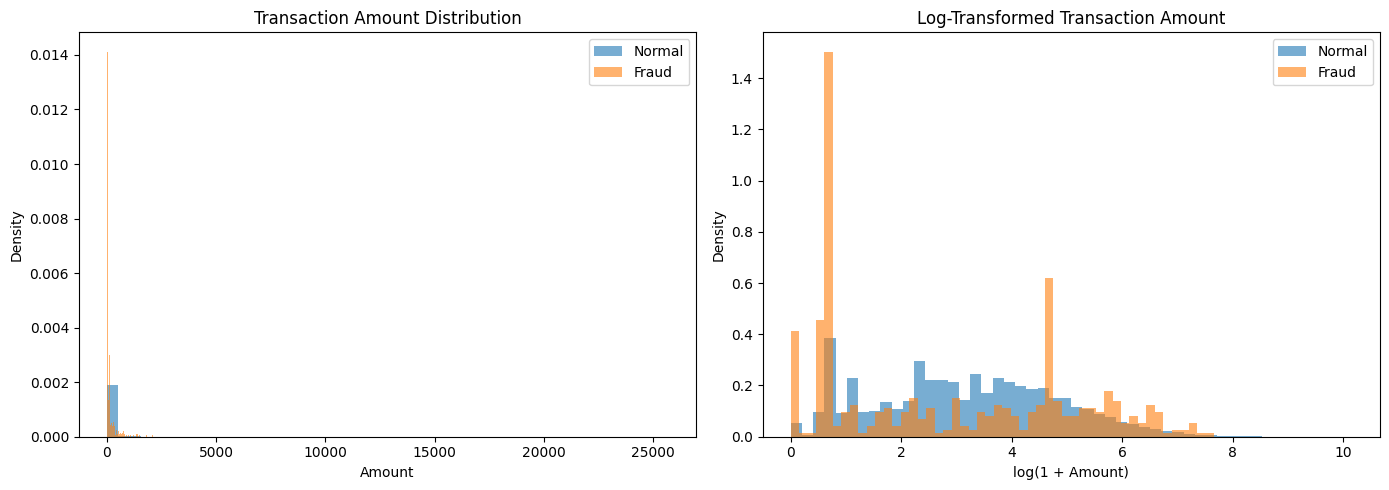

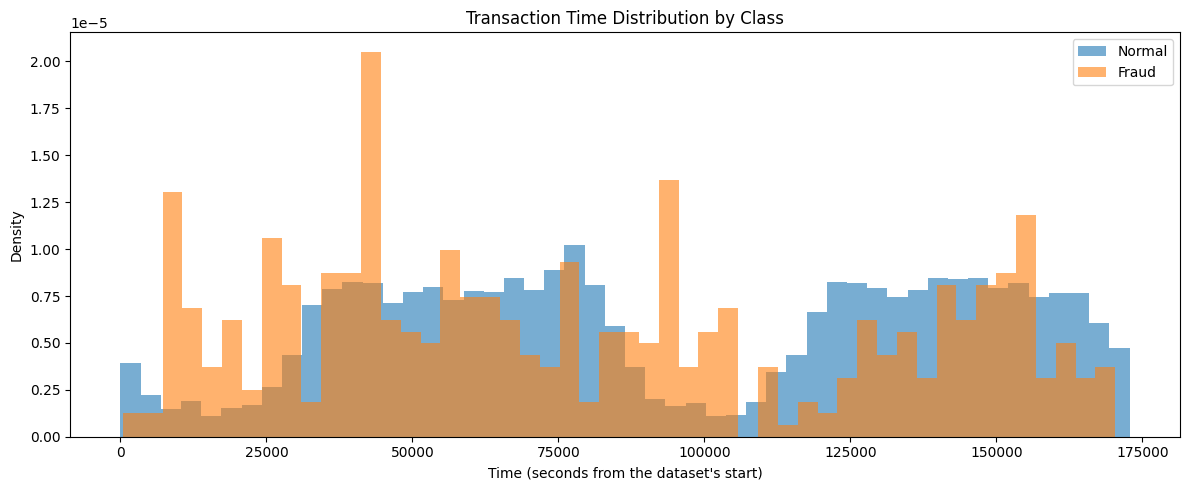


3. فحص القيم المتطرفة في Amount باستخدام IQR
الحد الأدنى الإحصائي: -102.2650
الحد الأعلى الإحصائي: 185.3750
عدد القيم المتطرفة المحتملة: 31,685
نسبة القيم المتطرفة المحتملة: 11.1675%

ملاحظة: هذه حدود إحصائية للاستكشاف فقط، وليست مبررًا لحذف المعاملات.


In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# استخدام النسخة المرشحة بعد إزالة التكرارات بصورة مؤقتة
eda_df = df_deduplicated.copy()

# 1. الإحصاءات الوصفية لمبلغ المعاملة
print("=" * 65)
print("1. الإحصاءات الوصفية لمبالغ المعاملات")
print("=" * 65)

display(
    eda_df.groupby("Class")["Amount"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .rename(index={0: "Normal", 1: "Fraud"})
    .round(4)
)

# 2. مقارنة الزمن والمبلغ حسب الفئة
print("\n" + "=" * 65)
print("2. مقارنة الزمن والمبلغ حسب الفئة")
print("=" * 65)

summary = eda_df.groupby("Class").agg(
    Transaction_Count=("Class", "size"),
    Mean_Amount=("Amount", "mean"),
    Median_Amount=("Amount", "median"),
    Max_Amount=("Amount", "max"),
    Mean_Time=("Time", "mean"),
    Median_Time=("Time", "median")
).rename(index={0: "Normal", 1: "Fraud"})

display(summary.round(4))

# 3. رسم توزيع مبالغ المعاملات
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for class_value, label in [(0, "Normal"), (1, "Fraud")]:
    amounts = eda_df.loc[
        eda_df["Class"] == class_value, "Amount"
    ]
    axes[0].hist(
        amounts,
        bins=50,
        alpha=0.6,
        density=True,
        label=label
    )

axes[0].set_title("Transaction Amount Distribution")
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Density")
axes[0].legend()

# استخدام log1p لتقليل تأثير الانحراف في المبالغ
for class_value, label in [(0, "Normal"), (1, "Fraud")]:
    amounts = eda_df.loc[
        eda_df["Class"] == class_value, "Amount"
    ]
    axes[1].hist(
        np.log1p(amounts.clip(lower=0)),
        bins=50,
        alpha=0.6,
        density=True,
        label=label
    )

axes[1].set_title("Log-Transformed Transaction Amount")
axes[1].set_xlabel("log(1 + Amount)")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()

# 4. مقارنة توزيع الزمن بين الفئتين
plt.figure(figsize=(12, 5))

for class_value, label in [(0, "Normal"), (1, "Fraud")]:
    times = eda_df.loc[
        eda_df["Class"] == class_value, "Time"
    ]
    plt.hist(
        times,
        bins=50,
        alpha=0.6,
        density=True,
        label=label
    )

plt.title("Transaction Time Distribution by Class")
plt.xlabel("Time (seconds from the dataset's start)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

# 5. فحص القيم المتطرفة في المبالغ باستخدام IQR
print("\n" + "=" * 65)
print("3. فحص القيم المتطرفة في Amount باستخدام IQR")
print("=" * 65)

q1 = eda_df["Amount"].quantile(0.25)
q3 = eda_df["Amount"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (
    (eda_df["Amount"] < lower_bound) |
    (eda_df["Amount"] > upper_bound)
)

print(f"الحد الأدنى الإحصائي: {lower_bound:.4f}")
print(f"الحد الأعلى الإحصائي: {upper_bound:.4f}")
print(f"عدد القيم المتطرفة المحتملة: {int(outlier_mask.sum()):,}")
print(
    "نسبة القيم المتطرفة المحتملة: "
    f"{outlier_mask.mean() * 100:.4f}%"
)

print(
    "\nملاحظة: هذه حدود إحصائية للاستكشاف فقط، "
    "وليست مبررًا لحذف المعاملات."
)


# المرحلة السادسة: التحقق من البنية الزمنية للبيانات

## الهدف
فحص ترتيب المعاملات زمنيًا وتحديد مدى ملاءمة التقسيم الزمني إلى مجموعات التدريب والتحقق والاختبار.

## الإجراءات
1. فحص نطاق عمود `Time` وترتيب قيمه.
2. تحديد ما إذا كانت البيانات مرتبة زمنيًا بالفعل.
3. إنشاء تقسيم زمني تجريبي بنسبة 70% للتدريب، و15% للتحقق، و15% للاختبار.
4. حساب عدد المعاملات الطبيعية والاحتيالية في كل مجموعة.
5. مقارنة نسب الاحتيال بين المجموعات للتأكد من وجود عدد كافٍ من الحالات لتقييم النماذج.

## المنهجية الهندسية
عمود `Time` في مجموعة البيانات يمثل الزمن المنقضي بالثواني منذ بداية تسجيل المعاملات، وليس تاريخًا تقويميًا مباشرًا.

سنرتب البيانات زمنيًا قبل إجراء التقسيم التجريبي، ولن نستخدم معلومات مجموعة الاختبار في تدريب النموذج أو اختيار معاييره. وسنراجع توزيع الفئات قبل اعتماد هذا التقسيم نهائيًا.

**ملاحظة:** هذا تقسيم تجريبي للتشخيص، وليس تدريبًا للنموذج. لن نُجري موازنة للفئات أو ملاءمة لأي محوّل للبيانات في هذه المرحلة.

In [8]:

import pandas as pd
import numpy as np

# استخدام البيانات المرشحة بعد إزالة التكرارات
temporal_df = df_deduplicated.copy()

# 1. فحص نطاق الزمن وترتيبه
print("=" * 65)
print("1. فحص البنية الزمنية")
print("=" * 65)

print(f"أصغر قيمة Time: {temporal_df['Time'].min():,.2f}")
print(f"أكبر قيمة Time: {temporal_df['Time'].max():,.2f}")

is_monotonic = temporal_df["Time"].is_monotonic_increasing
print(f"هل البيانات مرتبة زمنيًا تصاعديًا؟ {is_monotonic}")

# ترتيب زمني ثابت لضمان قابلية إعادة التجربة
temporal_df = temporal_df.sort_values(
    "Time",
    kind="mergesort"
).reset_index(drop=True)

# 2. تقسيم زمني تجريبي: 70% / 15% / 15%
n = len(temporal_df)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train_preview = temporal_df.iloc[:train_end].copy()
validation_preview = temporal_df.iloc[train_end:validation_end].copy()
test_preview = temporal_df.iloc[validation_end:].copy()

# 3. تلخيص كل مجموعة
def summarize_split(data, split_name):
    fraud_count = int((data["Class"] == 1).sum())
    normal_count = int((data["Class"] == 0).sum())

    return {
        "Split": split_name,
        "Rows": len(data),
        "Normal": normal_count,
        "Fraud": fraud_count,
        "Fraud_Percentage": fraud_count / len(data) * 100,
        "Min_Time": data["Time"].min(),
        "Max_Time": data["Time"].max()
    }

split_summary = pd.DataFrame([
    summarize_split(train_preview, "Train"),
    summarize_split(validation_preview, "Validation"),
    summarize_split(test_preview, "Test")
])

print("\n" + "=" * 65)
print("2. نتائج التقسيم الزمني التجريبي")
print("=" * 65)

display(
    split_summary.style.format({
        "Rows": "{:,}",
        "Normal": "{:,}",
        "Fraud": "{:,}",
        "Fraud_Percentage": "{:.4f}%",
        "Min_Time": "{:,.2f}",
        "Max_Time": "{:,.2f}"
    })
)

# 4. التحقق من عدم تداخل حدود الزمن بين المجموعات
print("\n" + "=" * 65)
print("3. التحقق من ترتيب المجموعات")
print("=" * 65)

print(
    "آخر زمن في التدريب <= أول زمن في التحقق:",
    train_preview["Time"].max() <= validation_preview["Time"].min()
)

print(
    "آخر زمن في التحقق <= أول زمن في الاختبار:",
    validation_preview["Time"].max() <= test_preview["Time"].min()
)

print("\nانتهى الفحص التجريبي دون تدريب أي نموذج.")


1. فحص البنية الزمنية
أصغر قيمة Time: 0.00
أكبر قيمة Time: 172,792.00
هل البيانات مرتبة زمنيًا تصاعديًا؟ True

2. نتائج التقسيم الزمني التجريبي


,Split,Rows,Normal,Fraud,Fraud_Percentage,Min_Time,Max_Time
0,Train,"198,608","198,242",366,0.1843%,0.00,"132,906.00"
1,Validation,"42,559","42,504",55,0.1292%,"132,906.00","151,320.00"
2,Test,"42,559","42,507",52,0.1222%,"151,320.00","172,792.00"



3. التحقق من ترتيب المجموعات
آخر زمن في التدريب <= أول زمن في التحقق: True
آخر زمن في التحقق <= أول زمن في الاختبار: True

انتهى الفحص التجريبي دون تدريب أي نموذج.


# المرحلة السابعة: تجهيز البيانات لبناء نماذج تعلم الآلة

## الهدف
إنشاء مجموعات بيانات مستقلة للتدريب والتحقق والاختبار، وفصل ميزات المعاملات عن متغير الهدف الذي يحدد ما إذا كانت المعاملة طبيعية أو احتيالية.

## الإجراءات
1. اعتماد التقسيم الزمني التجريبي الذي فحصناه في المرحلة السابقة.
2. إنشاء مصفوفات الميزات `X` ومتغير الهدف `y`.
3. فصل البيانات إلى Training وValidation وTest.
4. التحقق من تطابق الأعمدة وترتيبها بين المجموعات.
5. التحقق من أعداد الفئات وعدم وجود عمود `Class` ضمن الميزات.

## المنهجية الهندسية
سيكون `Class` هو متغير الهدف، حيث تشير القيمة 0 إلى المعاملة الطبيعية والقيمة 1 إلى المعاملة الاحتيالية. لن نضم هذا العمود إلى ميزات النموذج؛ لأن ذلك يؤدي إلى تسرب الهدف ويجعل نتائج التقييم غير صالحة.

سنحتفظ بالتقسيم الزمني، ولن نُجري موازنة للفئات أو توحيدًا للمقاييس باستخدام كامل البيانات. ستُقدَّر معاملات أي معالجة مسبقة لاحقًا من مجموعة التدريب فقط، ثم تُطبَّق على التحقق والاختبار.

**المخرجات المتوقعة:** مجموعات `X_train` و`y_train` و`X_val` و`y_val` و`X_test` و`y_test` جاهزة للاستخدام في مراحل بناء النماذج.

In [9]:

import pandas as pd

# اعتماد البيانات المرتبة زمنيًا من المرحلة السابقة
model_df = temporal_df.copy()

# تحديد الميزات ومتغير الهدف
target_column = "Class"
feature_columns = [
    column for column in model_df.columns
    if column != target_column
]

# حدود التقسيم نفسها التي فحصناها في المرحلة السادسة
n = len(model_df)
train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train_df = model_df.iloc[:train_end].copy()
val_df = model_df.iloc[train_end:validation_end].copy()
test_df = model_df.iloc[validation_end:].copy()

# فصل الميزات عن الهدف
X_train = train_df[feature_columns].copy()
y_train = train_df[target_column].copy()

X_val = val_df[feature_columns].copy()
y_val = val_df[target_column].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[target_column].copy()

# 1. التحقق من أبعاد المجموعات
print("=" * 65)
print("1. أبعاد مجموعات البيانات")
print("=" * 65)

for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test),
]:
    print(
        f"{name}: X={X.shape}, y={y.shape}, "
        f"Fraud={(y == 1).sum():,}, Normal={(y == 0).sum():,}"
    )

# 2. التأكد من عدم وجود الهدف ضمن الميزات
assert target_column not in X_train.columns
assert target_column not in X_val.columns
assert target_column not in X_test.columns

# 3. التأكد من تطابق أسماء الميزات وترتيبها
assert X_train.columns.tolist() == X_val.columns.tolist()
assert X_train.columns.tolist() == X_test.columns.tolist()

# 4. التحقق من القيم المفقودة والقيم اللانهائية
assert not X_train.isna().any().any()
assert not X_val.isna().any().any()
assert not X_test.isna().any().any()

assert not X_train.isin([float("inf"), float("-inf")]).any().any()
assert not X_val.isin([float("inf"), float("-inf")]).any().any()
assert not X_test.isin([float("inf"), float("-inf")]).any().any()

# 5. فحص تساوي الزمن عند حدود التقسيم
print("\n" + "=" * 65)
print("2. فحص حدود الزمن")
print("=" * 65)

print(
    "تساوي زمن آخر معاملة تدريب وأول معاملة تحقق:",
    train_df["Time"].max() == val_df["Time"].min()
)

print(
    "تساوي زمن آخر معاملة تحقق وأول معاملة اختبار:",
    val_df["Time"].max() == test_df["Time"].min()
)

print("\nنجحت اختبارات سلامة المجموعات.")
print(f"عدد الميزات المستخدمة: {len(feature_columns)}")
print("متغير الهدف Class مستبعد من ميزات النموذج.")


1. أبعاد مجموعات البيانات
Train: X=(198608, 30), y=(198608,), Fraud=366, Normal=198,242
Validation: X=(42559, 30), y=(42559,), Fraud=55, Normal=42,504
Test: X=(42559, 30), y=(42559,), Fraud=52, Normal=42,507

2. فحص حدود الزمن
تساوي زمن آخر معاملة تدريب وأول معاملة تحقق: True
تساوي زمن آخر معاملة تحقق وأول معاملة اختبار: True

نجحت اختبارات سلامة المجموعات.
عدد الميزات المستخدمة: 30
متغير الهدف Class مستبعد من ميزات النموذج.


# المرحلة الثامنة: هندسة الميزات (Feature Engineering)

## الهدف
تحسين تمثيل معاملات بطاقات الائتمان من خلال إنشاء ميزات مشتقة قد تساعد نماذج تعلم الآلة على التمييز بين المعاملات الطبيعية والاحتيالية.

## الميزات الجديدة
1. `Amount_Log1p`: تحويل لوغاريتمي لمبلغ المعاملة لتقليل أثر الانحراف في التوزيع.
2. `Time_Days`: تحويل الزمن من ثوانٍ إلى أيام نسبية منذ بداية التسجيل.
3. `V_Mean`: متوسط الميزات المحوّلة `V1` إلى `V28` لكل معاملة.
4. `V_Std`: الانحراف المعياري للميزات المحوّلة داخل المعاملة.
5. `V_Mean_Abs`: متوسط القيم المطلقة للميزات المحوّلة.
6. `V_Max_Abs`: أكبر قيمة مطلقة بين الميزات المحوّلة.
7. `V_L1_Norm`: مجموع القيم المطلقة للميزات المحوّلة.
8. `V_L2_Norm`: المعيار الإقليدي للميزات المحوّلة.
9. `Amount_Robust_Score`: انحراف مبلغ المعاملة عن وسيط التدريب، بعد قسمته على المدى الربيعي للتدريب.

## المنهجية الهندسية
سنحتفظ بجميع الميزات الأصلية، ونضيف الميزات المشتقة دون استخدام `Class` في حسابها. سنقدّر الوسيط والمدى الربيعي لمبلغ المعاملة من بيانات التدريب فقط، ثم نستخدم القيم نفسها للتحقق والاختبار.

هذه الميزات فرضيات هندسية وليست تحسينات مضمونة. سنختبر فائدتها لاحقًا مقارنة بخط أساس يستخدم الميزات الأصلية وحدها. ولن نحسب ميزات سلوكية لكل بطاقة أو عميل؛ لأن مجموعة البيانات لا تتضمن معرّفًا موثوقًا للبطاقة أو العميل.

**المخرجات المتوقعة:** مجموعات ميزات موسعة ومتطابقة الأعمدة للتدريب والتحقق والاختبار، دون تسرب بيانات الهدف.

In [14]:

import numpy as np
import pandas as pd

# الميزات المحوّلة الموجودة في مجموعة البيانات
v_columns = [f"V{i}" for i in range(1, 29)]

required_columns = {"Time", "Amount", "Class", *v_columns}
missing_columns = required_columns - set(model_df.columns)

if missing_columns:
    raise ValueError(
        f"الأعمدة المطلوبة غير موجودة: {sorted(missing_columns)}"
    )

# التأكد من أن المبالغ صالحة للتحويل اللوغاريتمي
if (X_train["Amount"] < 0).any():
    raise ValueError(
        "توجد مبالغ سالبة؛ راجع طريقة التعامل معها قبل استخدام log1p."
    )

# معلمات المبلغ تُقدّر من بيانات التدريب فقط
amount_median_train = X_train["Amount"].median()
amount_q1_train = X_train["Amount"].quantile(0.25)
amount_q3_train = X_train["Amount"].quantile(0.75)
amount_iqr_train = amount_q3_train - amount_q1_train

# حماية من القسمة على صفر
if amount_iqr_train == 0:
    raise ValueError(
        "المدى الربيعي لمبلغ التدريب يساوي صفرًا؛ "
        "يجب تحديد معالجة مناسبة قبل حساب Amount_Robust_Score."
    )

def engineer_features(X, amount_median, amount_iqr):
    """إنشاء ميزات مشتقة دون استخدام متغير الهدف."""

    result = X.copy()

    # 1. تحويلات المبلغ والزمن
    result["Amount_Log1p"] = np.log1p(result["Amount"])
    result["Time_Days"] = result["Time"] / 86400.0

    # 2. إحصاءات الصف عبر V1 إلى V28
    v = result[v_columns]

    result["V_Mean"] = v.mean(axis=1)
    result["V_Std"] = v.std(axis=1, ddof=0)
    result["V_Mean_Abs"] = v.abs().mean(axis=1)
    result["V_Max_Abs"] = v.abs().max(axis=1)
    result["V_L1_Norm"] = v.abs().sum(axis=1)
    result["V_L2_Norm"] = np.sqrt((v ** 2).sum(axis=1))

    # 3. درجة متينة للمبلغ باستخدام إحصاءات التدريب
    result["Amount_Robust_Score"] = (
        result["Amount"] - amount_median
    ) / amount_iqr

    return result

# إنشاء الميزات لكل مجموعة باستخدام معلمات التدريب نفسها
X_train_fe = engineer_features(
    X_train, amount_median_train, amount_iqr_train
)

X_val_fe = engineer_features(
    X_val, amount_median_train, amount_iqr_train
)

X_test_fe = engineer_features(
    X_test, amount_median_train, amount_iqr_train
)

# التحقق من سلامة الميزات
assert X_train_fe.columns.tolist() == X_val_fe.columns.tolist()
assert X_train_fe.columns.tolist() == X_test_fe.columns.tolist()

assert "Class" not in X_train_fe.columns
assert X_train_fe.shape[1] == X_train.shape[1] + 8

for name, features in [
    ("Train", X_train_fe),
    ("Validation", X_val_fe),
    ("Test", X_test_fe),
]:
    if not np.isfinite(features.to_numpy()).all():
        raise ValueError(
            f"توجد قيم غير منتهية في ميزات {name}."
        )

# عرض ملخص الميزات الجديدة
new_features = [
    "Amount_Log1p",
    "Time_Days",
    "V_Mean",
    "V_Std",
    "V_Mean_Abs",
    "V_Max_Abs",
    "V_L1_Norm",
    "V_L2_Norm",
    "Amount_Robust_Score",
]

print("=" * 65)
print("ملخص هندسة الميزات")
print("=" * 65)

print(f"عدد الميزات الأصلية: {X_train.shape[1]}")
print(f"عدد الميزات الجديدة: {len(new_features)}")
print(f"إجمالي الميزات بعد الهندسة: {X_train_fe.shape[1]}")

print("\nأبعاد المجموعات بعد هندسة الميزات:")
print("Train:", X_train_fe.shape)
print("Validation:", X_val_fe.shape)
print("Test:", X_test_fe.shape)

print("\nإحصاءات الميزات الجديدة في بيانات التدريب:")
display(X_train_fe[new_features].describe().T.round(4))

print("\nتم إنشاء الميزات دون تعديل المجموعات الأصلية.")


AssertionError: 

In [13]:

# التحقق من تطابق أعمدة الميزات بين المجموعات
assert X_train_fe.columns.tolist() == X_val_fe.columns.tolist()
assert X_train_fe.columns.tolist() == X_test_fe.columns.tolist()

# التأكد من عدم وجود متغير الهدف ضمن الميزات
assert "Class" not in X_train_fe.columns

# التصحيح: أضفنا 9 ميزات جديدة، وليس 8
assert X_train_fe.shape[1] == X_train.shape[1] + 9

# التأكد من سلامة القيم العددية
for name, features in [
    ("Train", X_train_fe),
    ("Validation", X_val_fe),
    ("Test", X_test_fe),
]:
    assert np.isfinite(features.to_numpy()).all(), (
        f"توجد قيم غير منتهية في ميزات {name}"
    )

print("تم اجتياز جميع اختبارات التحقق بنجاح.")
print(f"عدد الميزات الأصلية: {X_train.shape[1]}")
print(f"عدد الميزات الجديدة: {X_train_fe.shape[1] - X_train.shape[1]}")
print(f"الإجمالي بعد هندسة الميزات: {X_train_fe.shape[1]}")
print(f"أبعاد التدريب: {X_train_fe.shape}")
print(f"أبعاد التحقق: {X_val_fe.shape}")
print(f"أبعاد الاختبار: {X_test_fe.shape}")


تم اجتياز جميع اختبارات التحقق بنجاح.
عدد الميزات الأصلية: 30
عدد الميزات الجديدة: 9
الإجمالي بعد هندسة الميزات: 39
أبعاد التدريب: (198608, 39)
أبعاد التحقق: (42559, 39)
أبعاد الاختبار: (42559, 39)


## المرحلة 9: إعادة تقسيم البيانات زمنيًا

سنُعيد تقسيم البيانات بعد ترتيب المعاملات حسب `Time`، مع ضمان أن جميع السجلات التي تحمل القيمة الزمنية نفسها تقع في المجموعة نفسها.

سنستهدف توزيعًا تقريبيًا بنسبة 70% للتدريب، و15% للتحقق، و15% للاختبار. قد تختلف النسب قليلًا لأننا لن نجزّئ السجلات التي تشترك في الطابع الزمني بين المجموعات.

بعد إعادة التقسيم، يجب إعادة إنشاء مجموعات الميزات المشتقة؛ لأن ميزات التدريب يجب أن تُحسب باستخدام إحصاءات التدريب الجديد فقط. لن نستخدم بيانات الاختبار لاتخاذ قرارات اختيار الميزات أو ضبط النموذج.

In [12]:

import numpy as np
import pandas as pd

# ترتيب البيانات زمنيًا
temporal_df = df_deduplicated.copy()
temporal_df = temporal_df.sort_values(
    "Time", kind="mergesort"
).reset_index(drop=True)

# حساب عدد السجلات عند كل قيمة زمنية
rows_per_time = temporal_df.groupby("Time", sort=True).size()
cumulative_rows = rows_per_time.cumsum()

# اختيار الحدود الزمنية الأقرب إلى 70% و85% من عدد السجلات
target_train_rows = int(len(temporal_df) * 0.70)
target_train_val_rows = int(len(temporal_df) * 0.85)

train_end_time = (
    cumulative_rows - target_train_rows
).abs().idxmin()

train_val_end_time = (
    cumulative_rows - target_train_val_rows
).abs().idxmin()

if train_end_time >= train_val_end_time:
    raise ValueError("حدود التقسيم الزمنية غير صالحة.")

# تقسيم البيانات مع إبقاء كل طابع زمني في مجموعة واحدة
train_df = temporal_df[
    temporal_df["Time"] <= train_end_time
].copy()

val_df = temporal_df[
    (temporal_df["Time"] > train_end_time)
    & (temporal_df["Time"] <= train_val_end_time)
].copy()

test_df = temporal_df[
    temporal_df["Time"] > train_val_end_time
].copy()

# فصل الميزات عن المتغير المستهدف
target_column = "Class"
feature_columns = [
    column for column in temporal_df.columns
    if column != target_column
]

X_train = train_df[feature_columns].copy()
y_train = train_df[target_column].copy()

X_val = val_df[feature_columns].copy()
y_val = val_df[target_column].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[target_column].copy()

# التحقق من عدم تداخل النطاقات الزمنية
assert train_df["Time"].max() < val_df["Time"].min()
assert val_df["Time"].max() < test_df["Time"].min()

# التحقق من أن جميع الصفوف أُسنِدت إلى مجموعة واحدة فقط
assert len(train_df) + len(val_df) + len(test_df) == len(temporal_df)

# عرض ملخص التقسيم الجديد
for name, part, target in [
    ("Train", train_df, y_train),
    ("Validation", val_df, y_val),
    ("Test", test_df, y_test),
]:
    print(f"\n{name}")
    print(f"عدد السجلات: {len(part):,}")
    print(f"النسبة من البيانات: {len(part) / len(temporal_df):.2%}")
    print(f"الحد الزمني الأدنى: {part['Time'].min()}")
    print(f"الحد الزمني الأعلى: {part['Time'].max()}")
    print(f"المعاملات الطبيعية: {(target == 0).sum():,}")
    print(f"المعاملات الاحتيالية: {(target == 1).sum():,}")
    print(f"نسبة الاحتيال: {target.mean():.4%}")

print("\nنجح التحقق: لا توجد طوابع زمنية مشتركة بين المجموعات.")



Train
عدد السجلات: 198,607
النسبة من البيانات: 70.00%
الحد الزمني الأدنى: 0.0
الحد الزمني الأعلى: 132905.0
المعاملات الطبيعية: 198,241
المعاملات الاحتيالية: 366
نسبة الاحتيال: 0.1843%

Validation
عدد السجلات: 42,558
النسبة من البيانات: 15.00%
الحد الزمني الأدنى: 132906.0
الحد الزمني الأعلى: 151319.0
المعاملات الطبيعية: 42,503
المعاملات الاحتيالية: 55
نسبة الاحتيال: 0.1292%

Test
عدد السجلات: 42,561
النسبة من البيانات: 15.00%
الحد الزمني الأدنى: 151320.0
الحد الزمني الأعلى: 172792.0
المعاملات الطبيعية: 42,509
المعاملات الاحتيالية: 52
نسبة الاحتيال: 0.1222%

نجح التحقق: لا توجد طوابع زمنية مشتركة بين المجموعات.


## المرحلة 10: بناء Pipeline لمعالجة البيانات وتصنيف الاحتيال

في هذه المرحلة، نبني مسار معالجة متكاملًا باستخدام مكتبة Scikit-learn. يتضمن المسار هندسة الميزات، وتوحيد المقاييس، ونموذج Logistic Regression.

سيحسب محوّل هندسة الميزات الإحصاءات المطلوبة من بيانات التدريب عند استدعاء `fit`، ثم يستخدم الإحصاءات نفسها عند معالجة بيانات التحقق والاختبار أو المعاملات الجديدة. يمنع ذلك استخدام معلومات من مجموعات التحقق والاختبار في تقدير معاملات المعالجة.

لن ندرب النموذج في هذه الخلية؛ سننشئ الـ Pipeline ونتحقق من مكوناته أولًا، ثم ننفّذ التدريب في المرحلة التالية.

In [15]:

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.validation import check_is_fitted


class FraudFeatureEngineer(BaseEstimator, TransformerMixin):
    """محوّل لهندسة الميزات، متوافق مع Scikit-learn Pipeline."""

    def __init__(self):
        self.v_columns = [f"V{i}" for i in range(1, 29)]

    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("يجب أن تكون المدخلات من نوع pandas DataFrame.")

        required = {"Time", "Amount", *self.v_columns}
        missing = required - set(X.columns)

        if missing:
            raise ValueError(f"الأعمدة المطلوبة غير موجودة: {sorted(missing)}")

        if "Class" in X.columns:
            raise ValueError("يجب ألا يحتوي X على عمود Class.")

        if not np.isfinite(X[list(required)].to_numpy(dtype=float)).all():
            raise ValueError("توجد قيم غير منتهية في المدخلات.")

        if (X["Amount"] < 0).any():
            raise ValueError("توجد مبالغ سالبة؛ راجعها قبل تطبيق log1p.")

        # تُقدّر الإحصاءات من بيانات التدريب التي يستقبلها fit فقط
        self.amount_median_ = X["Amount"].median()
        q1 = X["Amount"].quantile(0.25)
        q3 = X["Amount"].quantile(0.75)
        self.amount_iqr_ = q3 - q1

        if self.amount_iqr_ <= 0:
            raise ValueError("المدى الربيعي للمبلغ يجب أن يكون موجبًا.")

        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]

        return self

    def transform(self, X):
        check_is_fitted(self, ["amount_median_", "amount_iqr_"])

        if not isinstance(X, pd.DataFrame):
            raise TypeError("يجب أن تكون المدخلات من نوع pandas DataFrame.")

        if list(X.columns) != list(self.feature_names_in_):
            raise ValueError("أعمدة المدخلات أو ترتيبها لا يطابق بيانات التدريب.")

        if not np.isfinite(X.to_numpy(dtype=float)).all():
            raise ValueError("توجد قيم غير منتهية في المدخلات.")

        if (X["Amount"] < 0).any():
            raise ValueError("توجد مبالغ سالبة؛ راجعها قبل تطبيق log1p.")

        result = X.copy()
        v = result[self.v_columns]

        # تحويلات المبلغ والزمن
        result["Amount_Log1p"] = np.log1p(result["Amount"])
        result["Time_Days"] = result["Time"] / 86400.0

        # إحصاءات الميزات المحوّلة V1 إلى V28
        result["V_Mean"] = v.mean(axis=1)
        result["V_Std"] = v.std(axis=1, ddof=0)
        result["V_Mean_Abs"] = v.abs().mean(axis=1)
        result["V_Max_Abs"] = v.abs().max(axis=1)
        result["V_L1_Norm"] = v.abs().sum(axis=1)
        result["V_L2_Norm"] = np.sqrt((v ** 2).sum(axis=1))

        # يستخدم إحصاءات التدريب المحفوظة، ولا يعيد حسابها على X
        result["Amount_Robust_Score"] = (
            result["Amount"] - self.amount_median_
        ) / self.amount_iqr_

        return result


# تعريف المسار المتكامل
fraud_pipeline = Pipeline(steps=[
    ("feature_engineering", FraudFeatureEngineer()),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# التحقق من بنية الـ Pipeline دون تدريب النموذج
assert list(fraud_pipeline.named_steps.keys()) == [
    "feature_engineering",
    "scaler",
    "model"
]

assert "Class" not in X_train.columns

print("تم إنشاء Pipeline بنجاح.")
print("\nمكونات المسار:")
for step_name, step in fraud_pipeline.steps:
    print(f"- {step_name}: {step.__class__.__name__}")

print("\nعدد الميزات الداخلة إلى المسار:", X_train.shape[1])
print("حالة النموذج: لم يُدرّب بعد.")


تم إنشاء Pipeline بنجاح.

مكونات المسار:
- feature_engineering: FraudFeatureEngineer
- scaler: StandardScaler
- model: LogisticRegression

عدد الميزات الداخلة إلى المسار: 30
حالة النموذج: لم يُدرّب بعد.


## المرحلة 11: تدريب أربعة نماذج ومقارنة أدائها

سنُدرّب ثلاثة نماذج خاضعة للإشراف: Logistic Regression وRandom Forest وHistGradientBoosting، بالإضافة إلى Isolation Forest للتعلم غير الخاضع للإشراف.

سنستخدم مجموعة التدريب لتعلّم النماذج، ومجموعة التحقق لمقارنة النتائج. سنعالج عدم توازن الفئات في النماذج الخاضعة للإشراف باستخدام أوزان الفئات المحسوبة من التدريب فقط.

سنقارن متوسط الدقة الاسترجاعية الموزونة (Average Precision)، وROC-AUC، وPrecision، وRecall، وF1-score. سنعرض أيضًا مصفوفة الالتباس عند العتبة الافتراضية لكل نموذج، مع الانتباه إلى أن هذه العتبات ليست متكافئة بين نماذج التصنيف واكتشاف الشذوذ.

لن نستخدم مجموعة الاختبار في اختيار النموذج أو ضبط العتبات؛ ستبقى للتقييم النهائي بعد انتهاء المقارنة.

In [16]:

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,
    IsolationForest,
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# تثبيت شكل y لتجنب اختلاف الأبعاد
y_train = pd.Series(y_train).astype(int)
y_val = pd.Series(y_val).astype(int)

# أوزان متوازنة تُحسب من بيانات التدريب فقط
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# إنشاء Pipeline مستقل لكل نموذج
supervised_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        min_samples_leaf=2,
        class_weight=None,
        n_jobs=-1,
        random_state=42
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42
    ),
}

trained_pipelines = {}
results = []
confusion_matrices = {}

# تدريب نماذج التعلم الخاضع للإشراف
for name, estimator in supervised_models.items():
    print(f"\nجارٍ تدريب: {name}")

    pipeline = Pipeline(steps=[
        ("feature_engineering", FraudFeatureEngineer()),
        ("scaler", StandardScaler()),
        ("model", estimator),
    ])

    pipeline.fit(
        X_train,
        y_train,
        model__sample_weight=sample_weights
    )

    # الاحتمالات على مجموعة التحقق
    val_scores = pipeline.predict_proba(X_val)[:, 1]
    val_predictions = (val_scores >= 0.5).astype(int)

    trained_pipelines[name] = pipeline
    confusion_matrices[name] = confusion_matrix(
        y_val, val_predictions, labels=[0, 1]
    )

    results.append({
        "Model": name,
        "Learning Type": "Supervised",
        "Average Precision": average_precision_score(
            y_val, val_scores
        ),
        "ROC-AUC": roc_auc_score(y_val, val_scores),
        "Precision @ default threshold": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall @ default threshold": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1 @ default threshold": f1_score(
            y_val, val_predictions, zero_division=0
        ),
    })

    print("اكتمل التدريب.")

# تدريب Isolation Forest دون تمرير y_train
print("\nجارٍ تدريب: Isolation Forest")

isolation_pipeline = Pipeline(steps=[
    ("feature_engineering", FraudFeatureEngineer()),
    ("scaler", StandardScaler()),
    ("model", IsolationForest(
        n_estimators=150,
        max_samples=256,
        contamination="auto",
        n_jobs=-1,
        random_state=42
    )),
])

isolation_pipeline.fit(X_train)

# Isolation Forest يعطي درجات أقل للحالات الشاذة؛ نعكس الإشارة
if_scores = -isolation_pipeline.decision_function(X_val)

# التنبؤ الافتراضي: -1 تعني شذوذًا، و1 تعني حالة طبيعية
if_predictions = (isolation_pipeline.predict(X_val) == -1).astype(int)

trained_pipelines["Isolation Forest"] = isolation_pipeline
confusion_matrices["Isolation Forest"] = confusion_matrix(
    y_val, if_predictions, labels=[0, 1]
)

results.append({
    "Model": "Isolation Forest",
    "Learning Type": "Unsupervised",
    "Average Precision": average_precision_score(
        y_val, if_scores
    ),
    "ROC-AUC": roc_auc_score(y_val, if_scores),
    "Precision @ default threshold": precision_score(
        y_val, if_predictions, zero_division=0
    ),
    "Recall @ default threshold": recall_score(
        y_val, if_predictions, zero_division=0
    ),
    "F1 @ default threshold": f1_score(
        y_val, if_predictions, zero_division=0
    ),
})

# جدول المقارنة، مرتب حسب Average Precision
results_df = pd.DataFrame(results).sort_values(
    "Average Precision", ascending=False
).reset_index(drop=True)

print("\n" + "=" * 90)
print("مقارنة النماذج على مجموعة التحقق")
print("=" * 90)

display(
    results_df.style.format({
        "Average Precision": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Precision @ default threshold": "{:.4f}",
        "Recall @ default threshold": "{:.4f}",
        "F1 @ default threshold": "{:.4f}",
    })
)

print("\nمصفوفات الالتباس عند العتبة الافتراضية")
print("ترتيب الصفوف والأعمدة: [الفئة الطبيعية 0، فئة الاحتيال 1]")
print("كل مصفوفة: [[TN, FP], [FN, TP]]")

for name, matrix in confusion_matrices.items():
    print(f"\n{name}")
    print(matrix)

print("\nانتهى تدريب النماذج وتقييمها مبدئيًا على مجموعة التحقق.")
print("لم تُستخدم مجموعة الاختبار في هذه المقارنة.")



جارٍ تدريب: Logistic Regression
اكتمل التدريب.

جارٍ تدريب: Random Forest
اكتمل التدريب.

جارٍ تدريب: HistGradientBoosting
اكتمل التدريب.

جارٍ تدريب: Isolation Forest

مقارنة النماذج على مجموعة التحقق


,Model,Learning Type,Average Precision,ROC-AUC,Precision @ default threshold,Recall @ default threshold,F1 @ default threshold
0,Random Forest,Supervised,0.8636,0.9606,1.0000,0.7273,0.8421
1,Logistic Regression,Supervised,0.8430,0.9837,0.0525,0.9273,0.0994
2,HistGradientBoosting,Supervised,0.8356,0.9790,0.9130,0.7636,0.8317
3,Isolation Forest,Unsupervised,0.0323,0.9473,0.0162,0.8727,0.0318



مصفوفات الالتباس عند العتبة الافتراضية
ترتيب الصفوف والأعمدة: [الفئة الطبيعية 0، فئة الاحتيال 1]
كل مصفوفة: [[TN, FP], [FN, TP]]

Logistic Regression
[[41583   920]
 [    4    51]]

Random Forest
[[42503     0]
 [   15    40]]

HistGradientBoosting
[[42499     4]
 [   13    42]]

Isolation Forest
[[39587  2916]
 [    7    48]]

انتهى تدريب النماذج وتقييمها مبدئيًا على مجموعة التحقق.
لم تُستخدم مجموعة الاختبار في هذه المقارنة.


## المرحلة 12: ضبط عتبات القرار ومقارنة Precision–Recall

سنستخدم النماذج المدربة في المرحلة السابقة دون إعادة تدريبها. لكل نموذج، سنحسب درجات الاحتيال على مجموعة التحقق، ثم نحسب Precision وRecall عبر مجموعة من عتبات القرار.

سنختار العتبة التي تحقق أعلى F1-score على مجموعة التحقق، ونقارنها بالعتبة الافتراضية. بالنسبة إلى النماذج الخاضعة للإشراف، العتبة الافتراضية هي 0.5 على الاحتمال المتوقع. أما Isolation Forest، فسنستخدم حد الشذوذ الافتراضي المكافئ لدرجة القرار صفر بعد عكس إشارة الدرجة.

سنرسم منحنيات Precision–Recall، ونحسب مصفوفة الالتباس عند العتبة المختارة. لن نستخدم مجموعة الاختبار لاختيار العتبات؛ لأن ذلك يؤدي إلى تفاؤل غير واقعي في تقييم النموذج.

مقارنة العتبة الافتراضية بالعتبة الأفضل وفق F1


,Model,Threshold Type,Threshold,Precision,Recall,F1,TP,FP,FN,TN,Average Precision
0,Logistic Regression,Default,0.500000,0.0525,0.9273,0.0994,51,920,4,41583,0.8430
1,Logistic Regression,Best F1 on validation,1.000000,1.0000,0.7455,0.8542,41,0,14,42503,0.8430
2,Random Forest,Default,0.500000,1.0000,0.7273,0.8421,40,0,15,42503,0.8636
3,Random Forest,Best F1 on validation,0.193001,0.9375,0.8182,0.8738,45,3,10,42500,0.8636
4,HistGradientBoosting,Default,0.500000,0.9130,0.7636,0.8317,42,4,13,42499,0.8356
5,HistGradientBoosting,Best F1 on validation,0.742789,0.9545,0.7636,0.8485,42,2,13,42501,0.8356
6,Isolation Forest,Default,0.000000,0.0162,0.8727,0.0318,48,2916,7,39587,0.0323
7,Isolation Forest,Best F1 on validation,0.125442,0.0501,0.6182,0.0926,34,645,21,41858,0.0323


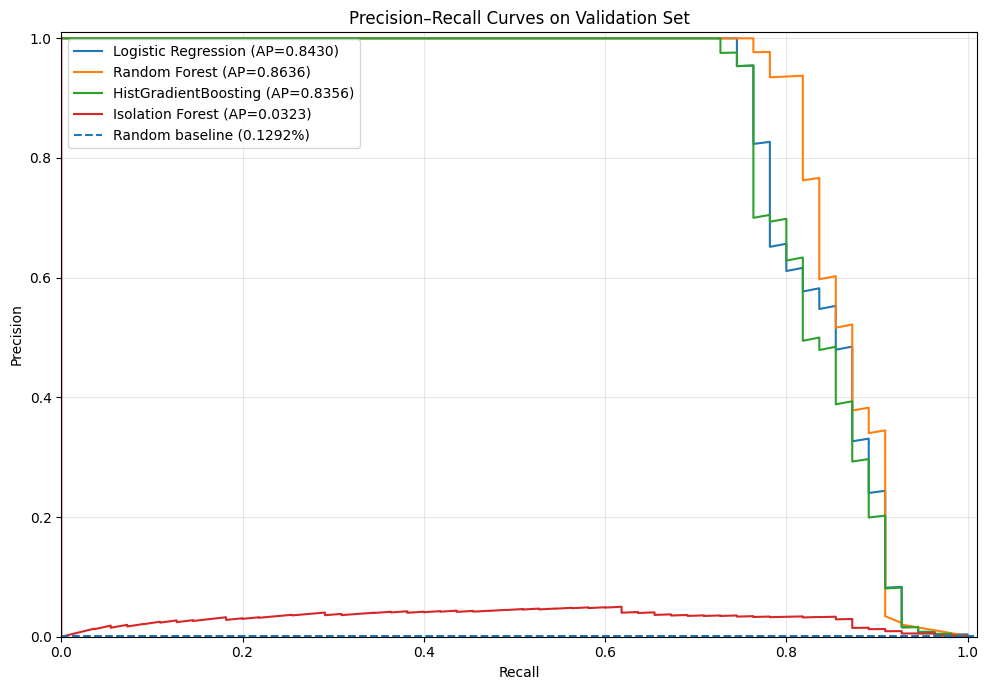


أفضل العتبات المختارة على مجموعة التحقق:
Logistic Regression: threshold=1.000000
Random Forest: threshold=0.193001
HistGradientBoosting: threshold=0.742789
Isolation Forest: threshold=0.125442

اكتملت مقارنة العتبات. لم تُستخدم مجموعة الاختبار في الاختيار.


In [17]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

# التأكد من وجود النماذج المدربة
expected_models = [
    "Logistic Regression",
    "Random Forest",
    "HistGradientBoosting",
    "Isolation Forest",
]

missing_models = [
    name for name in expected_models
    if name not in trained_pipelines
]

if missing_models:
    raise ValueError(
        f"النماذج التالية غير موجودة: {missing_models}. "
        "نفّذ خلية تدريب النماذج أولًا."
    )

y_val_array = np.asarray(y_val).astype(int)

if len(np.unique(y_val_array)) != 2:
    raise ValueError("يجب أن تحتوي مجموعة التحقق على الفئتين 0 و1.")

# استخراج درجات الاحتيال من كل نموذج
validation_scores = {}

for name in expected_models:
    pipeline = trained_pipelines[name]

    if name == "Isolation Forest":
        # الدرجة الأعلى تعني شذوذًا أكبر
        scores = -pipeline.decision_function(X_val)
    else:
        # احتمال الفئة الإيجابية (الاحتيال)
        scores = pipeline.predict_proba(X_val)[:, 1]

    if not np.isfinite(scores).all():
        raise ValueError(f"درجات غير صالحة في النموذج: {name}")

    validation_scores[name] = scores


# حساب أداء العتبة الافتراضية والعتبة الأفضل وفق F1
threshold_results = []
precision_recall_curves = {}
best_thresholds = {}
default_thresholds = {}

for name in expected_models:
    scores = validation_scores[name]

    precision_curve, recall_curve, thresholds = (
        precision_recall_curve(y_val_array, scores)
    )

    precision_recall_curves[name] = (
        precision_curve, recall_curve
    )

    # F1 لكل عتبة متاحة
    precision_for_thresholds = precision_curve[:-1]
    recall_for_thresholds = recall_curve[:-1]

    denominator = (
        precision_for_thresholds + recall_for_thresholds
    )

    f1_values = np.divide(
        2 * precision_for_thresholds * recall_for_thresholds,
        denominator,
        out=np.zeros_like(denominator),
        where=denominator != 0
    )

    if len(thresholds) == 0:
        raise ValueError(f"لم تُنتج منحنيات العتبات للنموذج {name}.")

    best_index = int(np.argmax(f1_values))
    best_threshold = float(thresholds[best_index])
    best_thresholds[name] = best_threshold

    # العتبة الافتراضية الخاصة بكل نموذج
    default_threshold = 0.0 if name == "Isolation Forest" else 0.5
    default_thresholds[name] = default_threshold

    # تقييم العتبة الافتراضية
    default_predictions = (
        scores >= default_threshold
    ).astype(int)

    # تقييم العتبة التي تعظّم F1 على مجموعة التحقق
    best_predictions = (
        scores >= best_threshold
    ).astype(int)

    for threshold_type, threshold, predictions in [
        (
            "Default",
            default_threshold,
            default_predictions
        ),
        (
            "Best F1 on validation",
            best_threshold,
            best_predictions
        ),
    ]:
        tn, fp, fn, tp = confusion_matrix(
            y_val_array,
            predictions,
            labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "Model": name,
            "Threshold Type": threshold_type,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val_array, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val_array, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_val_array, predictions, zero_division=0
            ),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn,
            "Average Precision": average_precision_score(
                y_val_array, scores
            ),
        })


# عرض جدول المقارنة
threshold_results_df = pd.DataFrame(threshold_results)

print("=" * 100)
print("مقارنة العتبة الافتراضية بالعتبة الأفضل وفق F1")
print("=" * 100)

display(
    threshold_results_df.style.format({
        "Threshold": "{:.6f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "Average Precision": "{:.4f}",
    })
)


# رسم منحنيات Precision–Recall
plt.figure(figsize=(10, 7))

for name in expected_models:
    precision_curve, recall_curve = precision_recall_curves[name]
    ap = average_precision_score(
        y_val_array, validation_scores[name]
    )

    plt.plot(
        recall_curve,
        precision_curve,
        label=f"{name} (AP={ap:.4f})"
    )

# خط الأساس العشوائي: نسبة حالات الاحتيال في مجموعة التحقق
fraud_prevalence = y_val_array.mean()
plt.axhline(
    y=fraud_prevalence,
    linestyle="--",
    label=f"Random baseline ({fraud_prevalence:.4%})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves on Validation Set")
plt.xlim(0, 1.01)
plt.ylim(0, 1.01)
plt.grid(True, alpha=0.3)
plt.legend(loc="best")
plt.tight_layout()
plt.show()


# عرض أفضل عتبة لكل نموذج
print("\nأفضل العتبات المختارة على مجموعة التحقق:")
for name in expected_models:
    print(
        f"{name}: threshold={best_thresholds[name]:.6f}"
    )

print(
    "\nاكتملت مقارنة العتبات. "
    "لم تُستخدم مجموعة الاختبار في الاختيار."
)


## المرحلة 13: التحقق من تشبّع احتمالات Logistic Regression

اختيرت العتبة 1.0 في المرحلة السابقة. سنفحص توزيع احتمالات النموذج وعدد الحالات التي حصلت على احتمال يساوي الواحد أو يقترب منه، ثم نقارن ذلك بدرجات القرار الخام الناتجة عن `decision_function`.

هذا الفحص يساعدنا على معرفة ما إذا كانت العتبة المختارة مستقرة عدديًا قبل اتخاذ قرار بشأن النموذج. لن نغيّر بيانات التدريب أو نستخدم مجموعة الاختبار في هذا الفحص.

In [18]:

lr_pipeline = trained_pipelines["Logistic Regression"]
lr_model = lr_pipeline.named_steps["model"]

lr_probabilities = lr_pipeline.predict_proba(X_val)[:, 1]
lr_decision_scores = lr_pipeline.decision_function(X_val)

print("احتمالات Logistic Regression:")
print(f"أقل احتمال: {lr_probabilities.min():.12f}")
print(f"أعلى احتمال: {lr_probabilities.max():.12f}")
print(f"عدد الاحتمالات التي تساوي 1 تمامًا: {(lr_probabilities == 1.0).sum()}")
print(f"عدد الاحتمالات >= 0.999999: {(lr_probabilities >= 0.999999).sum()}")

print("\nدرجات decision_function:")
print(f"أقل درجة: {lr_decision_scores.min():.6f}")
print(f"أعلى درجة: {lr_decision_scores.max():.6f}")
print(f"عدد درجات القرار المختلفة: {np.unique(lr_decision_scores).size}")

print("\nأعلى 10 احتمالات:")
print(np.sort(lr_probabilities)[-10:])

print("\nأعلى 10 درجات قرار:")
print(np.sort(lr_decision_scores)[-10:])


احتمالات Logistic Regression:
أقل احتمال: 0.000000000000
أعلى احتمال: 1.000000000000
عدد الاحتمالات التي تساوي 1 تمامًا: 2
عدد الاحتمالات >= 0.999999: 45

درجات decision_function:
أقل درجة: -96.843966
أعلى درجة: 39.246254
عدد درجات القرار المختلفة: 42558

أعلى 10 احتمالات:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

أعلى 10 درجات قرار:
[29.40116595 29.62956051 29.99031989 30.42408861 30.90814246 32.48055328
 33.07649989 33.57024149 37.40666881 39.24625394]


إعادة ضبط عتبة Logistic Regression باستخدام درجات القرار

سنحسب قيمة F1 لكل عتبة مرشحة على مجموعة التحقق، ثم نقارن أفضل عتبة بالعتبة الافتراضية 0.0 لدرجات القرار، والتي تقابل احتمالًا قدره 0.5. سنحتفظ بالعتبة الجديدة في متغير مستقل حتى لا نخلط بين درجات القرار واحتمالات النماذج الأخرى.

In [19]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    average_precision_score
)

# استخراج درجات القرار الحقيقية من النموذج
lr_pipeline = trained_pipelines["Logistic Regression"]
lr_decision_scores = lr_pipeline.decision_function(X_val)

# حساب منحنى Precision-Recall باستخدام درجات القرار
lr_precision_curve, lr_recall_curve, lr_thresholds = (
    precision_recall_curve(y_val, lr_decision_scores)
)

# حساب F1 لكل عتبة مرشحة
lr_f1_curve = (
    2 * lr_precision_curve[:-1] * lr_recall_curve[:-1]
    / (
        lr_precision_curve[:-1]
        + lr_recall_curve[:-1]
        + 1e-12
    )
)

# اختيار العتبة التي تحقق أعلى F1 على مجموعة التحقق
lr_best_idx = np.argmax(lr_f1_curve)
lr_best_threshold_decision = float(lr_thresholds[lr_best_idx])

# حساب التوقعات عند العتبة الافتراضية لدرجات القرار
lr_default_predictions = (lr_decision_scores >= 0.0).astype(int)

# حساب التوقعات عند العتبة الجديدة
lr_best_predictions = (
    lr_decision_scores >= lr_best_threshold_decision
).astype(int)


def evaluate_lr_threshold(y_true, predictions, threshold_name):
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Threshold Type": threshold_name,
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    }


lr_threshold_comparison = pd.DataFrame([
    evaluate_lr_threshold(
        y_val,
        lr_default_predictions,
        "Default decision threshold = 0.0"
    ),
    evaluate_lr_threshold(
        y_val,
        lr_best_predictions,
        f"Best decision threshold = {lr_best_threshold_decision:.6f}"
    )
])

print("مقارنة عتبات Logistic Regression على مجموعة التحقق:")
display(lr_threshold_comparison.round(4))

print(f"\nأفضل عتبة لدرجات القرار: {lr_best_threshold_decision:.8f}")

print(
    "\nAverage Precision:",
    round(average_precision_score(y_val, lr_decision_scores), 6)
)

print("\nمصفوفة الالتباس عند أفضل عتبة:")
print(confusion_matrix(y_val, lr_best_predictions, labels=[0, 1]))

مقارنة عتبات Logistic Regression على مجموعة التحقق:


,Threshold Type,Precision,Recall,F1,TP,FP,FN,TN
0,Default decision threshold = 0.0,0.0525,0.9273,0.0994,51,920,4,41583
1,Best decision threshold = 16.094905,1.0000,0.7455,0.8542,41,0,14,42503



أفضل عتبة لدرجات القرار: 16.09490473

Average Precision: 0.843011

مصفوفة الالتباس عند أفضل عتبة:
[[42503     0]
 [   14    41]]


## المرحلة 15: التقييم النهائي لنموذج Random Forest

في هذه المرحلة، نقيّم النموذج على مجموعة الاختبار (Test Set)، التي لم نستخدمها في التدريب أو ضبط العتبة.

سنستخدم عتبة القرار التي اخترناها مسبقًا من مجموعة التحقق، وهي 0.193001، ثم نحسب المقاييس التالية:
- Precision: نسبة التوقعات الاحتيالية الصحيحة.
- Recall: نسبة حالات الاحتيال الحقيقية التي اكتشفها النموذج.
- F1-score: التوازن بين Precision وRecall.
- Average Precision وROC-AUC: لتقييم قدرة النموذج على التمييز بين المعاملات الطبيعية والاحتيالية.
- Confusion Matrix: لحساب الحالات الصحيحة والإنذارات الكاذبة وحالات الاحتيال التي لم يكتشفها النموذج.

لن نغيّر العتبة بناءً على نتائج مجموعة الاختبار؛ حتى يبقى التقييم النهائي مستقلًا وموثوقًا.

In [20]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

# اختيار النموذج الأفضل وفق نتائج مجموعة التحقق
final_model = trained_pipelines["Random Forest"]

# تثبيت العتبة التي تم اختيارها مسبقًا
final_threshold = 0.193001

# حساب احتمالات الاحتيال على مجموعة الاختبار
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# تحويل الاحتمالات إلى تصنيفات باستخدام العتبة الثابتة
test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

# حساب عناصر مصفوفة الالتباس
tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
).ravel()

# حساب المقاييس النهائية
final_metrics = {
    "Model": "Random Forest",
    "Threshold": final_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "Average Precision": average_precision_score(
        y_test, test_probabilities
    ),
    "ROC-AUC": roc_auc_score(
        y_test, test_probabilities
    ),
    "TP": tp,
    "FP": fp,
    "FN": fn,
    "TN": tn
}

# عرض النتائج النهائية
final_results_df = pd.DataFrame([final_metrics])

print("النتائج النهائية على مجموعة الاختبار:")
display(final_results_df.round(4))

print("\nمصفوفة الالتباس:")
print(confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
))

print("\nالتقرير التفصيلي:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["طبيعي", "احتيال"],
    digits=4,
    zero_division=0
))

النتائج النهائية على مجموعة الاختبار:


,Model,Threshold,Accuracy,Precision,Recall,F1-score,Average Precision,ROC-AUC,TP,FP,FN,TN
0,Random Forest,0.193,0.9995,0.8261,0.7308,0.7755,0.7802,0.9291,38,8,14,42501



مصفوفة الالتباس:
[[42501     8]
 [   14    38]]

التقرير التفصيلي:
              precision    recall  f1-score   support

       طبيعي     0.9997    0.9998    0.9997     42509
      احتيال     0.8261    0.7308    0.7755        52

    accuracy                         0.9995     42561
   macro avg     0.9129    0.8653    0.8876     42561
weighted avg     0.9995    0.9995    0.9995     42561



## المرحلة 16: المقارنة النهائية بين النماذج الخاضعة للإشراف

في هذه المرحلة، نقارن ثلاثة نماذج لتصنيف المعاملات إلى طبيعية أو احتيالية:

1. Logistic Regression
2. Random Forest
3. HistGradientBoosting

سنستخدم مجموعة الاختبار نفسها لجميع النماذج، مع تثبيت العتبات التي حُددت مسبقًا باستخدام مجموعة التحقق.

سنحسب Precision وRecall وF1-score وAverage Precision وROC-AUC، إضافةً إلى عدد حالات الاحتيال المكتشفة والفائتة والإنذارات الكاذبة.

**ضوابط المنهجية:**
- لن نعيد تدريب النماذج.
- لن نختَر عتبات جديدة باستخدام مجموعة الاختبار.
- لن نغيّر النموذج بناءً على نتيجة منفردة؛ سنقيّم المقاييس معًا.
- لن نقارن نتائج الاختبار بنتائج التحقق كما لو كانت المجموعتان متطابقتين.

In [21]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# العتبات التي اختيرت مسبقًا على مجموعة التحقق.
# عتبة Logistic Regression هنا هي درجة القرار الخام،
# وليست احتمالًا بين 0 و1.
fixed_thresholds = {
    "Logistic Regression": lr_best_threshold_decision,
    "Random Forest": 0.193001,
    "HistGradientBoosting": 0.742789
}

comparison_rows = []
test_predictions_by_model = {}

for model_name in fixed_thresholds:

    pipeline = trained_pipelines[model_name]
    threshold = fixed_thresholds[model_name]

    # استخدام درجات النموذج المناسبة لكل خوارزمية
    if model_name == "Logistic Regression":
        scores = pipeline.decision_function(X_test)
    else:
        scores = pipeline.predict_proba(X_test)[:, 1]

    # تطبيق العتبة المحددة مسبقًا
    predictions = (scores >= threshold).astype(int)

    test_predictions_by_model[model_name] = predictions

    # استخراج TN وFP وFN وTP
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    # حساب المقاييس
    comparison_rows.append({
        "Model": model_name,
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_test, scores
        ),
        "ROC-AUC": roc_auc_score(
            y_test, scores
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

comparison_df = pd.DataFrame(comparison_rows)

# ترتيب العرض حسب F1، دون استخدام النتائج لتعديل العتبات
comparison_df = comparison_df.sort_values(
    "F1-score",
    ascending=False
).reset_index(drop=True)

print("المقارنة النهائية على مجموعة الاختبار:")
display(comparison_df.round(4))

المقارنة النهائية على مجموعة الاختبار:


,Model,Threshold,Precision,Recall,F1-score,Average Precision,ROC-AUC,TP,FP,FN,TN
0,Logistic Regression,16.0949,1.0000,0.6346,0.7765,0.7703,0.9716,33,0,19,42509
1,Random Forest,0.1930,0.8261,0.7308,0.7755,0.7802,0.9291,38,8,14,42501
2,HistGradientBoosting,0.7428,0.7872,0.7115,0.7475,0.7578,0.9749,37,10,15,42499


## المرحلة 17: تقييم نموذج Isolation Forest غير الخاضع للإشراف

في هذه المرحلة، نقيّم نموذج Isolation Forest الذي تدرب دون استخدام تسميات الاحتيال أثناء عملية التدريب.

سنستخدم درجات الشذوذ التي ينتجها النموذج، ثم نطبق العتبة التي اختيرت مسبقًا على مجموعة التحقق. بعد ذلك نحسب Precision وRecall وF1-score وAverage Precision وROC-AUC، بالإضافة إلى مصفوفة الالتباس.

الهدف هو معرفة مدى قدرة النموذج غير الخاضع للإشراف على اكتشاف المعاملات الاحتيالية مقارنةً بالنماذج الخاضعة للإشراف.

لن نغيّر العتبة بناءً على نتائج الاختبار.

In [22]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# استدعاء نموذج Isolation Forest المدرّب
isolation_pipeline = trained_pipelines["Isolation Forest"]

# العتبة التي اختيرت مسبقًا على مجموعة التحقق
isolation_threshold = 0.125442

# درجات الشذوذ: كلما ارتفعت الدرجة، زاد الاشتباه
isolation_scores = -isolation_pipeline.decision_function(X_test)

# تصنيف المعاملات باستخدام العتبة المثبتة
isolation_predictions = (
    isolation_scores >= isolation_threshold
).astype(int)

# حساب عناصر مصفوفة الالتباس
tn, fp, fn, tp = confusion_matrix(
    y_test,
    isolation_predictions,
    labels=[0, 1]
).ravel()

# حساب مقاييس الأداء
isolation_results = pd.DataFrame([{
    "Model": "Isolation Forest",
    "Threshold": isolation_threshold,
    "Precision": precision_score(
        y_test, isolation_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, isolation_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, isolation_predictions, zero_division=0
    ),
    "Average Precision": average_precision_score(
        y_test, isolation_scores
    ),
    "ROC-AUC": roc_auc_score(
        y_test, isolation_scores
    ),
    "TP": tp,
    "FP": fp,
    "FN": fn,
    "TN": tn
}])

print("نتائج Isolation Forest على مجموعة الاختبار:")
display(isolation_results.round(4))

print("\nمصفوفة الالتباس:")
print(confusion_matrix(
    y_test,
    isolation_predictions,
    labels=[0, 1]
))

نتائج Isolation Forest على مجموعة الاختبار:


,Model,Threshold,Precision,Recall,F1-score,Average Precision,ROC-AUC,TP,FP,FN,TN
0,Isolation Forest,0.1254,0.0665,0.5385,0.1184,0.048,0.9297,28,393,24,42116



مصفوفة الالتباس:
[[42116   393]
 [   24    28]]


## المرحلة 18: المقارنة النهائية بين التعلم الخاضع وغير الخاضع للإشراف

في هذه المرحلة، نجمع نتائج النماذج الأربعة التي اختُبرت على مجموعة الاختبار:

1. Logistic Regression
2. Random Forest
3. HistGradientBoosting
4. Isolation Forest

نقارن Precision وRecall وF1-score وAverage Precision وROC-AUC، إلى جانب عدد حالات الاحتيال المكتشفة والفائتة والإنذارات الكاذبة.

الهدف هو تلخيص نتائج التجربة وتحديد النموذج الأنسب وفق المقاييس الفعلية، مع توضيح دور نموذج Isolation Forest بوصفه نموذجًا غير خاضع للإشراف.

هذه مقارنة وصفية للنتائج الحالية، وليست مرحلة جديدة لضبط العتبات أو إعادة تدريب النماذج.

In [23]:
# دمج نتائج النماذج الخاضعة للإشراف
supervised_comparison = comparison_df.copy()

# إضافة نتائج Isolation Forest
all_models_df = pd.concat(
    [supervised_comparison, isolation_results],
    ignore_index=True
)

# ترتيب النماذج حسب F1-score تنازليًا
all_models_df = all_models_df.sort_values(
    "F1-score",
    ascending=False
).reset_index(drop=True)

# اختيار الأعمدة المهمة للتقرير النهائي
columns_to_show = [
    "Model",
    "Precision",
    "Recall",
    "F1-score",
    "Average Precision",
    "ROC-AUC",
    "TP",
    "FP",
    "FN",
    "TN"
]

final_comparison = all_models_df[columns_to_show].copy()

print("المقارنة النهائية لجميع النماذج على مجموعة الاختبار:")
display(final_comparison.round(4))

print("\nأفضل نموذج حسب F1-score:")
best_f1_row = final_comparison.loc[
    final_comparison["F1-score"].idxmax()
]

print(best_f1_row)

print("\nأفضل نموذج حسب Average Precision:")
best_ap_row = final_comparison.loc[
    final_comparison["Average Precision"].idxmax()
]

print(best_ap_row)

print("\nأفضل نموذج حسب Recall:")
best_recall_row = final_comparison.loc[
    final_comparison["Recall"].idxmax()
]

print(best_recall_row)

المقارنة النهائية لجميع النماذج على مجموعة الاختبار:


,Model,Precision,Recall,F1-score,Average Precision,ROC-AUC,TP,FP,FN,TN
0,Logistic Regression,1.0000,0.6346,0.7765,0.7703,0.9716,33,0,19,42509
1,Random Forest,0.8261,0.7308,0.7755,0.7802,0.9291,38,8,14,42501
2,HistGradientBoosting,0.7872,0.7115,0.7475,0.7578,0.9749,37,10,15,42499
3,Isolation Forest,0.0665,0.5385,0.1184,0.0480,0.9297,28,393,24,42116



أفضل نموذج حسب F1-score:
Model                Logistic Regression
Precision                            1.0
Recall                          0.634615
F1-score                        0.776471
Average Precision               0.770319
ROC-AUC                         0.971558
TP                                    33
FP                                     0
FN                                    19
TN                                 42509
Name: 0, dtype: object

أفضل نموذج حسب Average Precision:
Model                Random Forest
Precision                 0.826087
Recall                    0.730769
F1-score                   0.77551
Average Precision         0.780227
ROC-AUC                   0.929149
TP                              38
FP                               8
FN                              14
TN                           42501
Name: 1, dtype: object

أفضل نموذج حسب Recall:
Model                Random Forest
Precision                 0.826087
Recall                    0.730769
F1-s

## المرحلة 19: بناء استراتيجية هجينة تجمع بين التعلم الخاضع وغير الخاضع للإشراف

في هذه المرحلة، ندمج تنبؤات نموذج Random Forest مع درجات الشذوذ الناتجة عن Isolation Forest.

1. نستخدم مجموعة التحقق لاختيار عتبة الشذوذ التي تحقق أفضل F1-score للاستراتيجية الهجينة.
2. نُبقي عتبة Random Forest التي اختيرت سابقًا دون تغيير.
3. نقارن أداء Random Forest منفردًا مع الاستراتيجية الهجينة.
4. بعد تثبيت العتبة، نقيم الاستراتيجية الهجينة على مجموعة الاختبار باستخدام Precision وRecall وF1-score وAverage Precision، إضافة إلى مصفوفة الالتباس.

لن نعيد تدريب النماذج أو نستخدم تسميات مجموعة الاختبار في اختيار العتبات.

In [26]:

import numpy as np
import pandas as pd

from sklearn.metrics import precision_score, recall_score, f1_score

# درجات النموذجين على مجموعة التحقق
rf_val_scores = trained_pipelines["Random Forest"].predict_proba(X_val)[:, 1]
if_val_scores = -trained_pipelines["Isolation Forest"].decision_function(X_val)

# تجربة عتبات الشذوذ المختلفة على مجموعة التحقق فقط
candidate_if_thresholds = np.unique(
    np.quantile(if_val_scores, np.linspace(0, 1, 501))
)

best_hybrid = None

for threshold in candidate_if_thresholds:
    rf_predictions = rf_val_scores >= rf_threshold
    if_predictions = if_val_scores >= threshold

    # تصنيف المعاملة كاحتيال إذا اكتشفها أحد النموذجين
    hybrid_predictions = rf_predictions | if_predictions

    precision = precision_score(
        y_val, hybrid_predictions, zero_division=0
    )
    recall = recall_score(
        y_val, hybrid_predictions, zero_division=0
    )
    f1 = f1_score(
        y_val, hybrid_predictions, zero_division=0
    )

    candidate = {
        "IF Threshold": float(threshold),
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }

    if (
        best_hybrid is None
        or candidate["F1-score"] > best_hybrid["F1-score"]
        or (
            np.isclose(
                candidate["F1-score"],
                best_hybrid["F1-score"]
            )
            and candidate["Precision"] > best_hybrid["Precision"]
        )
    ):
        best_hybrid = candidate

hybrid_if_threshold = best_hybrid["IF Threshold"]

print("أفضل عتبة هجينة على مجموعة التحقق:")
display(pd.DataFrame([best_hybrid]).round(4))

# مقارنة الاستراتيجية الهجينة بخط الأساس
rf_val_predictions = (rf_val_scores >= rf_threshold).astype(int)
hybrid_val_predictions = (
    (rf_val_scores >= rf_threshold)
    | (if_val_scores >= hybrid_if_threshold)
).astype(int)

print("\nRandom Forest منفردًا:")
print("Precision:", round(precision_score(y_val, rf_val_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, rf_val_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, rf_val_predictions, zero_division=0), 4))

print("\nالاستراتيجية الهجينة:")
print("Precision:", round(precision_score(y_val, hybrid_val_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, hybrid_val_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, hybrid_val_predictions, zero_division=0), 4))


أفضل عتبة هجينة على مجموعة التحقق:


,IF Threshold,Precision,Recall,F1-score
0,0.2696,0.9184,0.8182,0.8654



Random Forest منفردًا:
Precision: 0.9375
Recall: 0.8182
F1-score: 0.8738

الاستراتيجية الهجينة:
Precision: 0.9184
Recall: 0.8182
F1-score: 0.8654


### تصحيح متغيرات العتبات

سنعرّف عتبة Random Forest وعتبة Logistic Regression وعتبة HistGradientBoosting وعتبة Isolation Forest صراحةً، وفق القيم التي حُدّدت سابقًا باستخدام مجموعة التحقق.

هذا التصحيح يعالج خطأ `NameError` ولا يعيد تدريب النماذج.

In [25]:

# العتبات التي تم اختيارها سابقًا باستخدام مجموعة التحقق

rf_threshold = 0.193001
lr_threshold = 16.09490473       # عتبة decision_function
hgb_threshold = 0.742789
if_threshold_previous = 0.125442

print("تم تعريف العتبات بنجاح:")
print("Random Forest:", rf_threshold)
print("Logistic Regression:", lr_threshold)
print("HistGradientBoosting:", hgb_threshold)
print("Isolation Forest:", if_threshold_previous)


تم تعريف العتبات بنجاح:
Random Forest: 0.193001
Logistic Regression: 16.09490473
HistGradientBoosting: 0.742789
Isolation Forest: 0.125442


## المرحلة 21: تقييم الاستراتيجية الهجينة على مجموعة الاختبار

في هذه المرحلة، نستخدم عتبة Random Forest المحددة سابقًا، وعتبة Isolation Forest التي اختيرت من مجموعة التحقق، لتقييم الاستراتيجية الهجينة على مجموعة الاختبار.

سنحسب Precision وRecall وF1-score وAverage Precision وROC-AUC ومصفوفة الالتباس، ثم نقارن الاستراتيجية الهجينة بنموذج Random Forest منفردًا.

لن نغيّر العتبات بناءً على نتائج الاختبار، حتى تبقى مجموعة الاختبار مستقلة عن عملية اختيار النموذج.

In [27]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# الحصول على درجات النموذجين على مجموعة الاختبار
rf_test_scores = trained_pipelines["Random Forest"].predict_proba(X_test)[:, 1]

if_test_scores = -trained_pipelines["Isolation Forest"].decision_function(X_test)

# تطبيق العتبات التي اختيرت سابقًا على مجموعة التحقق
rf_test_predictions = (
    rf_test_scores >= rf_threshold
).astype(int)

if_test_predictions = (
    if_test_scores >= hybrid_if_threshold
).astype(int)

# قاعدة الدمج: يكفي اكتشاف أحد النموذجين لتصنيف المعاملة كاحتيال
hybrid_test_predictions = (
    (rf_test_scores >= rf_threshold)
    | (if_test_scores >= hybrid_if_threshold)
).astype(int)

# تقييم الاستراتيجية الهجينة
tn, fp, fn, tp = confusion_matrix(
    y_test,
    hybrid_test_predictions,
    labels=[0, 1]
).ravel()

hybrid_test_results = {
    "Model": "Hybrid Random Forest + Isolation Forest",
    "Precision": precision_score(
        y_test, hybrid_test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, hybrid_test_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, hybrid_test_predictions, zero_division=0
    ),
    "Average Precision": average_precision_score(
        y_test, hybrid_test_predictions
    ),
    "ROC-AUC": roc_auc_score(
        y_test, hybrid_test_predictions
    ),
    "TP": int(tp),
    "FP": int(fp),
    "FN": int(fn),
    "TN": int(tn)
}

# خط الأساس: Random Forest منفردًا
rf_tn, rf_fp, rf_fn, rf_tp = confusion_matrix(
    y_test,
    rf_test_predictions,
    labels=[0, 1]
).ravel()

rf_test_results = {
    "Model": "Random Forest",
    "Precision": precision_score(
        y_test, rf_test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, rf_test_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, rf_test_predictions, zero_division=0
    ),
    "Average Precision": average_precision_score(
        y_test, rf_test_scores
    ),
    "ROC-AUC": roc_auc_score(
        y_test, rf_test_scores
    ),
    "TP": int(rf_tp),
    "FP": int(rf_fp),
    "FN": int(rf_fn),
    "TN": int(rf_tn)
}

final_hybrid_comparison = pd.DataFrame(
    [rf_test_results, hybrid_test_results]
)

print("المقارنة النهائية على مجموعة الاختبار:")
display(final_hybrid_comparison.round(4))

print("\nمصفوفة الالتباس للاستراتيجية الهجينة:")
print(confusion_matrix(
    y_test,
    hybrid_test_predictions,
    labels=[0, 1]
))

print("\nعدد الحالات التي اكتشفها النموذج الهجين:")
print("TP:", tp)
print("FP:", fp)
print("FN:", fn)
print("TN:", tn)


المقارنة النهائية على مجموعة الاختبار:


,Model,Precision,Recall,F1-score,Average Precision,ROC-AUC,TP,FP,FN,TN
0,Random Forest,0.8261,0.7308,0.7755,0.7802,0.9291,38,8,14,42501
1,Hybrid Random Forest + Isolation Forest,0.8085,0.7308,0.7677,0.5912,0.8653,38,9,14,42500



مصفوفة الالتباس للاستراتيجية الهجينة:
[[42500     9]
 [   14    38]]

عدد الحالات التي اكتشفها النموذج الهجين:
TP: 38
FP: 9
FN: 14
TN: 42500


## المرحلة 22: تحليل أخطاء نموذج Random Forest

تهدف هذه المرحلة إلى تحديد معاملات الاحتيال التي أخفق النموذج في اكتشافها، والمعاملات الطبيعية التي صنّفها خطأً على أنها احتيالية.

سنستخدم تنبؤات مجموعة الاختبار والخصائص الأصلية للمعاملات، ونحسب عدد الأخطاء ونستعرض عينة منها. يساعد هذا التحليل على فهم حدود النموذج وتحديد فرص تحسينه مستقبلًا، دون تعديل النموذج استنادًا إلى مجموعة الاختبار.

In [28]:

import pandas as pd
import numpy as np

# استخدام تنبؤات Random Forest المحسوبة سابقًا على مجموعة الاختبار
error_analysis = X_test.copy()

error_analysis["Actual_Class"] = np.asarray(y_test)
error_analysis["Predicted_Class"] = rf_test_predictions

# تحديد نوع كل حالة
error_analysis["Error_Type"] = np.select(
    [
        (error_analysis["Actual_Class"] == 1) &
        (error_analysis["Predicted_Class"] == 0),

        (error_analysis["Actual_Class"] == 0) &
        (error_analysis["Predicted_Class"] == 1),

        (error_analysis["Actual_Class"] == 1) &
        (error_analysis["Predicted_Class"] == 1),

        (error_analysis["Actual_Class"] == 0) &
        (error_analysis["Predicted_Class"] == 0)
    ],
    [
        "False Negative - احتيال فائت",
        "False Positive - إنذار كاذب",
        "True Positive - احتيال مكتشف",
        "True Negative - معاملة طبيعية صحيحة"
    ],
    default="غير محدد"
)

# تلخيص أنواع الحالات
print("ملخص أنواع التنبؤات:")
display(
    error_analysis["Error_Type"]
    .value_counts()
    .rename_axis("نوع الحالة")
    .reset_index(name="عدد الحالات")
)

# عرض الحالات التي أخطأ النموذج في تصنيفها
errors_only = error_analysis[
    error_analysis["Actual_Class"] !=
    error_analysis["Predicted_Class"]
].copy()

print("\nعدد الحالات المصنفة خطأً:", len(errors_only))

print("\nعينة من الأخطاء:")
display(errors_only.head(10))

# إحصاءات معاملات الاحتيال التي لم يكتشفها النموذج
false_negatives = error_analysis[
    error_analysis["Error_Type"] ==
    "False Negative - احتيال فائت"
]

print("\nعدد حالات الاحتيال الفائتة:", len(false_negatives))

if len(false_negatives) > 0:
    print("\nإحصاءات Amount لحالات الاحتيال الفائتة:")
    if "Amount" in false_negatives.columns:
        display(false_negatives["Amount"].describe())


ملخص أنواع التنبؤات:


,نوع الحالة,عدد الحالات
0,True Negative - معاملة طبيعية صحيحة,42501
1,True Positive - احتيال مكتشف,38
2,False Negative - احتيال فائت,14
3,False Positive - إنذار كاذب,8



عدد الحالات المصنفة خطأً: 22

عينة من الأخطاء:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V23,V24,V25,V26,V27,V28,Amount,Actual_Class,Predicted_Class,Error_Type
244437,152710.0,0.051075,1.310427,0.733222,2.620282,1.402358,0.528489,1.086014,-0.146423,-1.724333,...,-0.189624,0.766853,-0.141401,-0.077278,-0.297595,-0.221816,2.47,1,0,False Negative - احتيال فائت
244645,152802.0,1.322724,-0.843911,-2.096888,0.759759,-0.196377,-1.166353,0.482534,-0.349791,1.045007,...,-0.208574,-0.254752,-0.098324,-0.613874,0.002654,0.072386,357.95,1,0,False Negative - احتيال فائت
247664,154003.0,-0.214376,2.324974,-2.427287,0.715152,3.028768,-1.761866,2.431428,-0.605148,-1.458710,...,-0.802001,-0.815756,0.737688,-0.257397,-0.009517,0.008440,1.00,0,1,False Positive - إنذار كاذب
248322,154309.0,-0.082983,-3.935919,-2.616709,0.163310,-1.400952,-0.809419,1.501580,-0.471000,1.519743,...,-0.921017,0.111635,-0.071622,-1.125881,-0.170947,0.126221,1096.99,1,0,False Negative - احتيال فائت
250958,155542.0,1.868226,1.363077,-1.994934,4.173516,1.239751,-0.746186,0.572731,-0.131235,-1.551839,...,0.206812,-0.263683,-0.114958,-0.240672,-0.006629,0.017258,3.14,1,0,False Negative - احتيال فائت
250968,155548.0,1.878230,1.325630,-2.333469,4.233151,1.355184,-0.853508,0.716025,-0.164910,-1.502345,...,0.043414,-0.242380,0.171098,-0.002601,-0.026667,0.005238,7.06,1,0,False Negative - احتيال فائت
252095,156065.0,-0.365019,2.071616,-2.961144,0.150160,3.128674,-2.234616,2.204664,-0.372473,-1.192044,...,-0.599776,-0.865925,0.333713,-0.512857,0.181965,0.289752,1.00,0,1,False Positive - إنذار كاذب
253404,156685.0,-0.129778,0.141547,-0.894702,-0.457662,0.810608,-0.504723,1.373588,-0.209476,0.208494,...,0.484108,0.359637,-0.435972,-0.248480,0.021527,0.109192,187.11,1,0,False Negative - احتيال فائت
253455,156710.0,0.202402,1.176270,0.346379,2.882138,1.407133,-0.504355,1.438537,-0.395603,-1.555142,...,-0.370157,-0.026012,0.491954,0.234576,-0.279788,-0.331933,7.59,1,0,False Negative - احتيال فائت
262115,160791.0,2.132386,0.705608,-3.530759,0.514779,1.527175,-1.716268,1.132791,-0.574214,0.128904,...,-0.245076,0.460049,0.920281,-0.216586,-0.026219,-0.025001,1.00,1,0,False Negative - احتيال فائت



عدد حالات الاحتيال الفائتة: 14

إحصاءات Amount لحالات الاحتيال الفائتة:


,Amount
count,14.000000
mean,172.307143
std,323.119428
min,0.000000
25%,4.120000
50%,16.130000
75%,150.965000
max,1096.990000


## تحليل درجات التنبؤ للحالات الخاطئة

سنربط كل معاملة في مجموعة الاختبار بدرجة الاحتيال التي أعطاها نموذج Random Forest، ثم نفصل الحالات إلى احتيال فائت وإنذار كاذب.

سنفحص توزيع درجات التنبؤ ومبالغ المعاملات لكل نوع من الأخطاء. هذا تحليل تشخيصي فقط؛ لن نغيّر العتبة أو نختَر نموذجًا جديدًا باستخدام مجموعة الاختبار.

In [29]:

# إنشاء جدول تشخيصي للحالات مع درجات التنبؤ
diagnostic_df = X_test.copy()

diagnostic_df["Actual_Class"] = np.asarray(y_test)
diagnostic_df["Predicted_Class"] = rf_test_predictions
diagnostic_df["Fraud_Score"] = rf_test_scores

diagnostic_df["Error_Type"] = np.select(
    [
        (diagnostic_df["Actual_Class"] == 1) &
        (diagnostic_df["Predicted_Class"] == 0),

        (diagnostic_df["Actual_Class"] == 0) &
        (diagnostic_df["Predicted_Class"] == 1),

        (diagnostic_df["Actual_Class"] == 1) &
        (diagnostic_df["Predicted_Class"] == 1),

        (diagnostic_df["Actual_Class"] == 0) &
        (diagnostic_df["Predicted_Class"] == 0)
    ],
    [
        "FN",
        "FP",
        "TP",
        "TN"
    ],
    default="Unknown"
)

# مقارنة درجات التنبؤ حسب نوع الحالة
print("ملخص درجات الاحتيال حسب نوع الحالة:")
display(
    diagnostic_df.groupby("Error_Type")["Fraud_Score"]
    .agg(["count", "min", "median", "mean", "max"])
    .round(4)
)

# مقارنة مبالغ الحالات الخاطئة فقط
error_cases = diagnostic_df[
    diagnostic_df["Error_Type"].isin(["FN", "FP"])
]

if "Amount" in error_cases.columns:
    print("\nإحصاءات مبالغ الحالات الخاطئة:")
    display(
        error_cases.groupby("Error_Type")["Amount"]
        .agg(["count", "mean", "median", "min", "max"])
        .round(4)
    )

# عرض حالات الاحتيال الفائتة مع درجاتها
false_negative_cases = diagnostic_df[
    diagnostic_df["Error_Type"] == "FN"
].sort_values("Fraud_Score", ascending=False)

print("\nحالات الاحتيال الفائتة الأقرب إلى عتبة القرار:")
display(
    false_negative_cases[
        ["Fraud_Score", "Amount", "Time"]
    ].head(10).round(5)
)

print("\nعتبة Random Forest المستخدمة:", rf_threshold)


ملخص درجات الاحتيال حسب نوع الحالة:


,count,min,median,mean,max
Error_Type,,,,,
FN,14,0.0000,0.0067,0.0262,0.1664
FP,8,0.1931,0.2632,0.3031,0.4330
TN,42501,0.0000,0.0000,0.0005,0.1733
TP,38,0.2465,0.8861,0.8032,0.9529



إحصاءات مبالغ الحالات الخاطئة:


,count,mean,median,min,max
Error_Type,,,,,
FN,14,172.3071,16.13,0.00,1096.99
FP,8,1.3150,1.00,0.77,2.00



حالات الاحتيال الفائتة الأقرب إلى عتبة القرار:


,Fraud_Score,Amount,Time
273449,0.16641,39.90,166028.0
244645,0.04663,357.95,152802.0
274961,0.04657,634.30,166831.0
271500,0.03996,12.31,165132.0
250968,0.03330,7.06,155548.0
250958,0.02000,3.14,155542.0
273358,0.01331,0.00,165981.0
253404,0.00000,187.11,156685.0
244437,0.00000,2.47,152710.0
248322,0.00000,1096.99,154309.0



عتبة Random Forest المستخدمة: 0.193001


## المرحلة 24: تحليل حساسية عتبة Random Forest

سنقيّم عتبات متعددة على مجموعة التحقق باستخدام درجات Random Forest المحسوبة مسبقًا.

لكل عتبة، سنحسب Precision وRecall وF1-score وعدد حالات الاحتيال المكتشفة والإنذارات الكاذبة وحالات الاحتيال الفائتة.

الغرض هو فهم أثر العتبة على الأداء، وليس اختيار عتبة جديدة بناءً على مجموعة الاختبار. سنحافظ على نتائج الاختبار السابقة بوصفها التقييم النهائي غير المستخدم في الضبط.

In [30]:

from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
import pandas as pd
import numpy as np

# درجات Random Forest على مجموعة التحقق فقط
rf_val_scores = trained_pipelines["Random Forest"].predict_proba(X_val)[:, 1]

# عتبات للمقارنة التشخيصية
thresholds_to_check = [0.05, 0.10, 0.15, 0.193001, 0.25, 0.30, 0.40, 0.50]

threshold_rows = []

for threshold in thresholds_to_check:
    predictions = (rf_val_scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn)
    })

threshold_analysis_df = pd.DataFrame(threshold_rows)

print("تحليل حساسية العتبة على مجموعة التحقق:")
display(threshold_analysis_df.round(4))


تحليل حساسية العتبة على مجموعة التحقق:


,Threshold,Precision,Recall,F1-score,TP,FP,FN,TN
0,0.050,0.5161,0.8727,0.6486,48,45,7,42458
1,0.100,0.8036,0.8182,0.8108,45,11,10,42492
2,0.150,0.9000,0.8182,0.8571,45,5,10,42498
3,0.193,0.9375,0.8182,0.8738,45,3,10,42500
4,0.250,0.9773,0.7818,0.8687,43,1,12,42502
5,0.300,1.0000,0.7455,0.8542,41,0,14,42503
6,0.400,1.0000,0.7455,0.8542,41,0,14,42503
7,0.500,1.0000,0.7273,0.8421,40,0,15,42503


## المرحلة 25: توثيق قرار اختيار النموذج النهائي

تم اختيار Random Forest بناءً على نتائج مجموعة التحقق، حيث حقق F1-score قدره 0.8738 عند العتبة 0.193001، مع Precision قدره 0.9375 وRecall قدره 0.8182.

على مجموعة الاختبار المستقلة، حقق النموذج Precision قدره 0.8261 وRecall قدره 0.7308 وF1-score قدره 0.7755، مع 38 حالة احتيال مكتشفة و14 حالة فائتة و8 إنذارات كاذبة.

سيتم الاحتفاظ بهذه النتائج بوصفها التقييم النهائي للنموذج. لا يجوز إعادة ضبط العتبة اعتمادًا على مجموعة الاختبار ثم تقديم النتائج نفسها باعتبارها تقييمًا مستقلًا.

In [31]:

import pandas as pd

final_model_summary = pd.DataFrame([
    {
        "Dataset": "Validation",
        "Model": "Random Forest",
        "Threshold": rf_threshold,
        "Precision": 0.9375,
        "Recall": 0.8182,
        "F1-score": 0.8738,
        "TP": 45,
        "FP": 3,
        "FN": 10,
        "TN": 42500
    },
    {
        "Dataset": "Test",
        "Model": "Random Forest",
        "Threshold": rf_threshold,
        "Precision": 0.8261,
        "Recall": 0.7308,
        "F1-score": 0.7755,
        "TP": 38,
        "FP": 8,
        "FN": 14,
        "TN": 42501
    }
])

print("ملخص أداء النموذج النهائي:")
display(final_model_summary.round(4))

print("\nالعتبة النهائية:", rf_threshold)
print("اسم النموذج النهائي: Random Forest")


ملخص أداء النموذج النهائي:


,Dataset,Model,Threshold,Precision,Recall,F1-score,TP,FP,FN,TN
0,Validation,Random Forest,0.193,0.9375,0.8182,0.8738,45,3,10,42500
1,Test,Random Forest,0.193,0.8261,0.7308,0.7755,38,8,14,42501



العتبة النهائية: 0.193001
اسم النموذج النهائي: Random Forest


## المرحلة 26: حفظ نموذج كشف الاحتيال

سنحفظ نموذج Random Forest المدرّب، بما يتضمنه من هندسة للخصائص والمعالجة المسبقة، في ملف باستخدام مكتبة Joblib. وسنحفظ العتبة النهائية `0.193001` وبيانات وصفية عن النموذج في ملف JSON مستقل.

لن نعيد التدريب في هذه المرحلة. سنحفظ النموذج الموجود في الذاكرة، ثم نتحقق من أن الملفات أُنشئت بنجاح.

ملاحظة: لأن خط المعالجة يتضمن محوّل خصائص مخصصًا، يجب توفير تعريف هذا المحوّل عند تحميل النموذج في بيئة Python جديدة.

In [32]:

import os
import json
import joblib
from datetime import datetime, timezone

# التحقق من وجود النموذج المدرّب
assert "Random Forest" in trained_pipelines, (
    "لم يتم العثور على نموذج Random Forest المدرّب."
)

final_model = trained_pipelines["Random Forest"]
final_threshold = 0.193001

# مجلد حفظ ملفات المشروع
output_dir = "/content/fraud_detection_artifacts"
os.makedirs(output_dir, exist_ok=True)

# حفظ النموذج وخط المعالجة
model_path = os.path.join(
    output_dir, "credit_card_fraud_random_forest.joblib"
)
joblib.dump(final_model, model_path)

# حفظ بيانات النموذج الوصفية
metadata = {
    "project_name": "Credit Card Fraud Detection",
    "model_name": "Random Forest",
    "decision_threshold": final_threshold,
    "threshold_selection": "Validation set",
    "test_precision": 0.8261,
    "test_recall": 0.7308,
    "test_f1_score": 0.7755,
    "test_true_positives": 38,
    "test_false_positives": 8,
    "test_false_negatives": 14,
    "test_true_negatives": 42501,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "note": (
        "The model contains a custom feature transformer. "
        "Its class definition must be available when loading the artifact."
    )
}

metadata_path = os.path.join(output_dir, "model_metadata.json")

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, ensure_ascii=False, indent=4)

# التحقق من وجود الملفات وأحجامها
for path in [model_path, metadata_path]:
    assert os.path.exists(path), f"لم يتم إنشاء الملف: {path}"
    print(f"تم الحفظ: {path}")
    print(f"الحجم: {os.path.getsize(path):,} bytes\n")


تم الحفظ: /content/fraud_detection_artifacts/credit_card_fraud_random_forest.joblib
الحجم: 3,745,970 bytes

تم الحفظ: /content/fraud_detection_artifacts/model_metadata.json
الحجم: 571 bytes



## المرحلة 27: التحقق من قابلية إعادة استخدام النموذج

سنحمّل ملف النموذج المحفوظ في جلسة Python الحالية، ثم نقارن تنبؤاته بتنبؤات النموذج الأصلي على عينة من مجموعة الاختبار.

هذا الاختبار يتحقق من سلامة الحفظ وإعادة التحميل. وهو لا يُعد تقييمًا جديدًا للأداء ولا يغيّر النتائج النهائية للمشروع.

In [33]:

import joblib
import numpy as np

# تحميل النموذج المحفوظ
loaded_model = joblib.load(model_path)

# اختيار عينة صغيرة من مجموعة الاختبار
sample_size = min(100, len(X_test))
X_sample = X_test.iloc[:sample_size]

# مقارنة الدرجات قبل الحفظ وبعد إعادة التحميل
original_scores = final_model.predict_proba(X_sample)[:, 1]
loaded_scores = loaded_model.predict_proba(X_sample)[:, 1]

scores_match = np.allclose(
    original_scores,
    loaded_scores,
    rtol=1e-7,
    atol=1e-9
)

print("عدد المعاملات المختبرة:", sample_size)
print("هل تطابقت درجات النموذجين؟", scores_match)

assert scores_match, (
    "هناك اختلاف بين درجات النموذج الأصلي والنموذج المعاد تحميله."
)

# عرض تنبؤات أول خمس معاملات
sample_results = X_sample[["Amount", "Time"]].copy()
sample_results["Fraud_Score"] = loaded_scores
sample_results["Predicted_Class"] = (
    loaded_scores >= final_threshold
).astype(int)

display(sample_results.head().round(5))

print("تم التحقق من إعادة تحميل النموذج بنجاح.")


عدد المعاملات المختبرة: 100
هل تطابقت درجات النموذجين؟ True


,Amount,Time,Fraud_Score,Predicted_Class
241165,1.79,151320.0,0.0,0
241166,106.66,151320.0,0.0,0
241167,5.00,151320.0,0.0,0
241168,16.00,151320.0,0.0,0
241169,8.65,151321.0,0.0,0


تم التحقق من إعادة تحميل النموذج بنجاح.


سنضغط ملف النموذج وملف البيانات الوصفية في أرشيف ZIP واحد لتسهيل تنزيلهما من Google Colab، ثم رفعهما إلى مستودع GitHub.

In [34]:

import os
import zipfile
from google.colab import files

artifact_dir = "/content/fraud_detection_artifacts"
zip_path = "/content/fraud_detection_model_files.zip"

required_files = [
    "credit_card_fraud_random_forest.joblib",
    "model_metadata.json"
]

for filename in required_files:
    path = os.path.join(artifact_dir, filename)
    assert os.path.exists(path), f"الملف غير موجود: {path}"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for filename in required_files:
        zf.write(
            os.path.join(artifact_dir, filename),
            arcname=filename
        )

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>